## Análisis Exploratorio de Datos (EDA)

In [62]:
import pandas as pd


from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

import statsmodels.api as sm
from scipy import stats
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
import numpy as np
import warnings

import warnings
warnings.filterwarnings('ignore')
from scipy import stats
from statsmodels.tsa.stattools import adfuller, kpss

from statsmodels.tsa.stattools import grangercausalitytests
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
import warnings; warnings.filterwarnings('ignore')

In [3]:
base=pd.read_csv("../data/raw/wti_market_data_20261021.csv")

In [4]:
base

,Date,WTI,VIX,DXY,GOLD,TNX,SP500,NG
0,2010-01-04,81.510002,20.040001,77.529999,1117.699951,3.841,1132.989990,5.884
1,2010-01-05,81.769997,19.350000,77.620003,1118.099976,3.755,1136.520020,5.637
2,2010-01-06,83.180000,19.160000,77.489998,1135.900024,3.808,1137.140015,6.009
3,2010-01-07,82.660004,19.059999,77.910004,1133.099976,3.822,1141.689941,5.806
4,2010-01-08,82.750000,18.129999,77.470001,1138.199951,3.808,1144.979980,5.749
...,...,...,...,...,...,...,...,...
4227,2026-10-14,95.089996,16.870001,102.550003,4107.899902,5.190,7718.939941,3.198
4228,2026-10-15,97.970001,16.459999,102.000000,4170.100098,5.089,7744.060059,3.236
4229,2026-10-16,101.410004,19.990000,101.839996,4181.100098,5.098,7659.439941,3.116
4230,2026-10-19,103.660004,18.440001,101.980003,4160.100098,5.136,7690.729980,3.058


In [5]:
# Muestra el conteo exacto de valores nulos por columna
print(base.isnull().sum())

Date     0
WTI      7
VIX      5
DXY      6
GOLD     7
TNX      9
SP500    7
NG       6
dtype: int64


In [6]:
base[base.isnull().any(axis=1)]

,Date,WTI,VIX,DXY,GOLD,TNX,SP500,NG
194,2010-10-11,82.209999,18.959999,77.440002,1353.300049,NaN,1165.319946,3.601
1520,2016-01-18,NaN,NaN,99.120003,NaN,NaN,NaN,NaN
1705,2016-10-10,NaN,13.380000,NaN,NaN,1.723,2163.659912,NaN
1729,2016-11-11,NaN,14.170000,NaN,NaN,NaN,2164.449951,NaN
2032,2018-01-29,65.559998,13.840000,89.309998,NaN,2.699,2853.530029,3.631
3498,2023-11-23,NaN,NaN,NaN,1993.300049,NaN,NaN,2.934
3781,2025-01-09,73.919998,NaN,109.180000,2690.800049,NaN,NaN,3.701
3875,2025-05-26,NaN,NaN,98.930000,NaN,NaN,NaN,NaN
3903,2025-07-04,66.500000,NaN,NaN,3346.500000,NaN,NaN,3.387
4127,2026-05-25,NaN,16.590000,NaN,NaN,NaN,NaN,NaN


In [7]:
def delete_null_rows(base, threshold=0.05):
    # Creamos un DataFrame que combine la cantidad y el porcentaje de nulos
    df_nulos = pd.DataFrame({
        'Cantidad Nulos': base.isnull().sum(),
        'Porcentaje (%)': (base.isnull().mean() * 100).round(2)
    })
    df_nulos.sort_values(by='Cantidad Nulos', ascending=False)

    if df_nulos["Porcentaje (%)"].mean()<=(threshold*100):
        base = base.dropna()
        print(f"Se eliminaron {df_nulos['Cantidad Nulos'].sum()} valores nulos.")
        print(f"El nuevo dataframe tiene {base.shape[0]} filas y {base.shape[1]} columnas.")
    return base

In [8]:
base1=delete_null_rows(base, threshold=0.05)

Se eliminaron 47 valores nulos.
El nuevo dataframe tiene 4221 filas y 8 columnas.


In [9]:
# 1. Date como índice datetime
base1['Date'] = pd.to_datetime(base1['Date'])
base1 = base1.set_index('Date').sort_index()
print(base1.index.dtype, base1.index.is_monotonic_increasing, base1.index.duplicated().sum())


datetime64[us] True 0


In [10]:
base1

,WTI,VIX,DXY,GOLD,TNX,SP500,NG
Date,,,,,,,
2010-01-04,81.510002,20.040001,77.529999,1117.699951,3.841,1132.989990,5.884
2010-01-05,81.769997,19.350000,77.620003,1118.099976,3.755,1136.520020,5.637
2010-01-06,83.180000,19.160000,77.489998,1135.900024,3.808,1137.140015,6.009
2010-01-07,82.660004,19.059999,77.910004,1133.099976,3.822,1141.689941,5.806
2010-01-08,82.750000,18.129999,77.470001,1138.199951,3.808,1144.979980,5.749
...,...,...,...,...,...,...,...
2026-10-14,95.089996,16.870001,102.550003,4107.899902,5.190,7718.939941,3.198
2026-10-15,97.970001,16.459999,102.000000,4170.100098,5.089,7744.060059,3.236
2026-10-16,101.410004,19.990000,101.839996,4181.100098,5.098,7659.439941,3.116


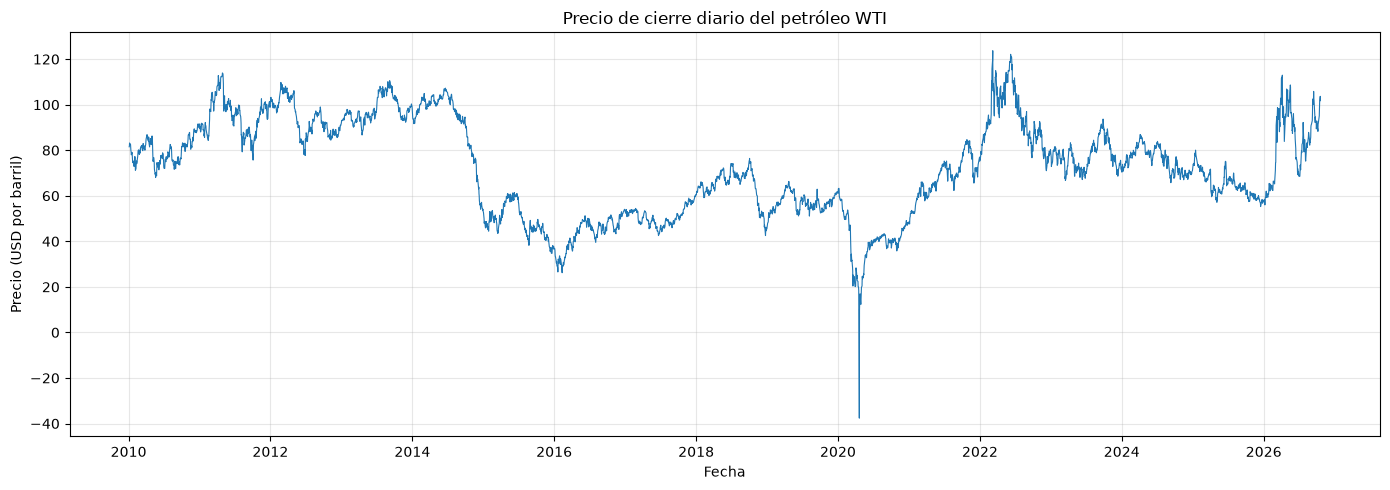

In [11]:

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(base1.index, base1["WTI"], linewidth=0.8)

ax.set_title("Precio de cierre diario del petróleo WTI")
ax.set_xlabel("Fecha")
ax.set_ylabel("Precio (USD por barril)")

ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()


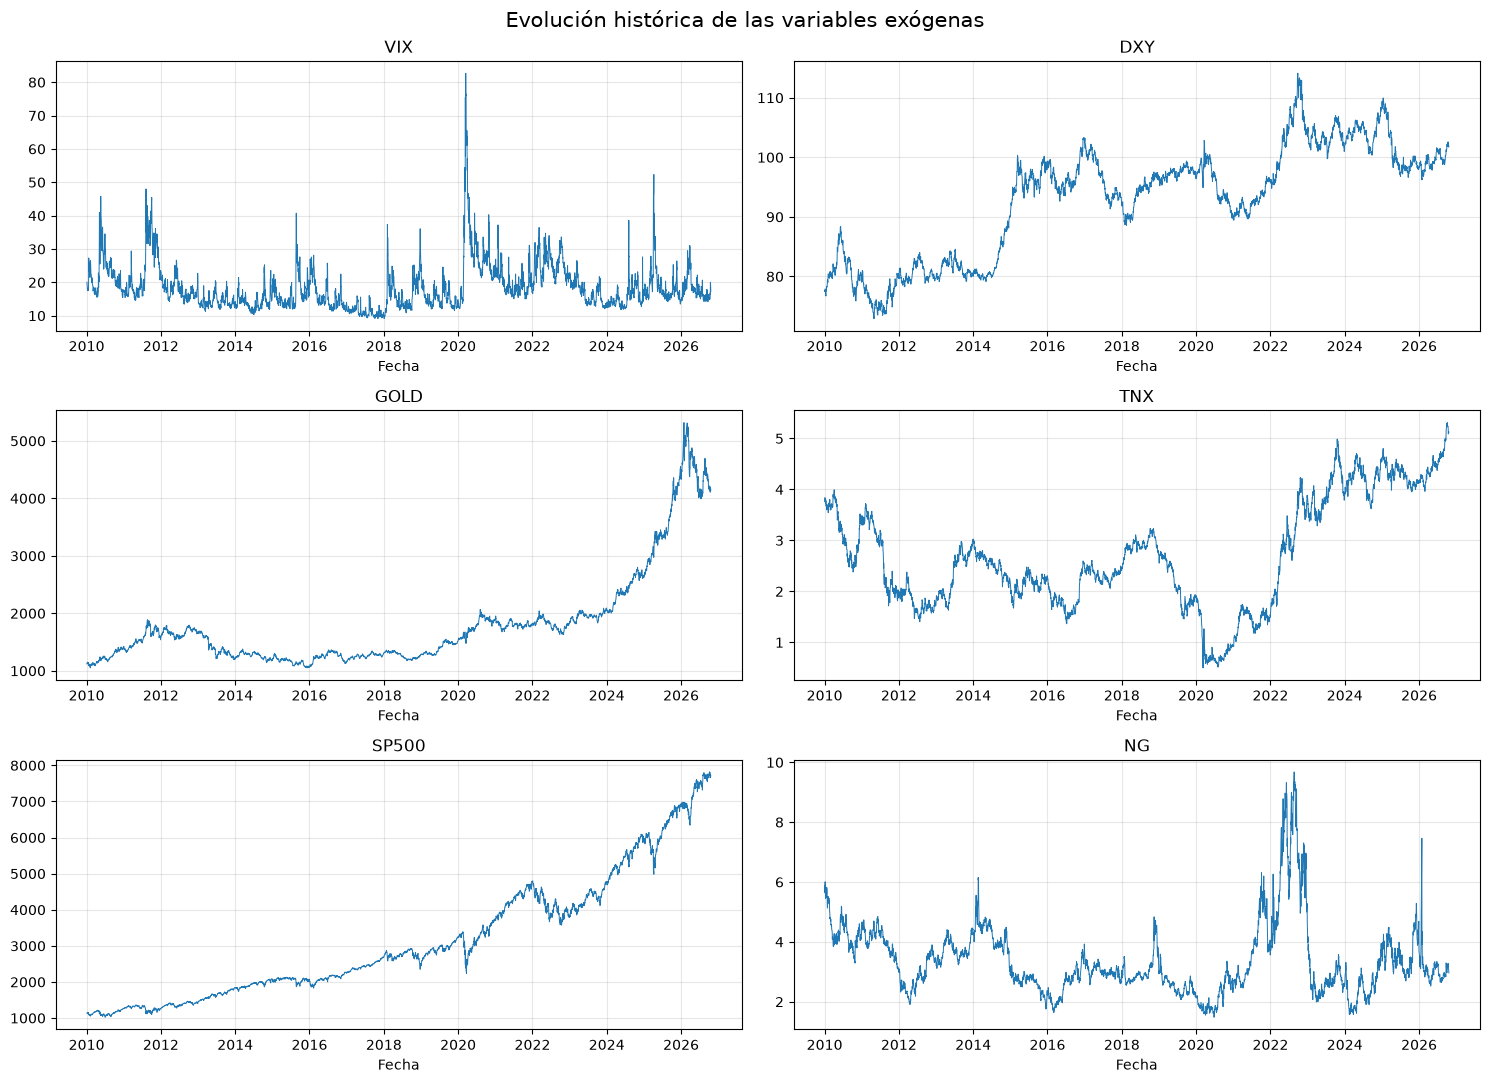

In [12]:

exogenous = ["VIX", "DXY", "GOLD", "TNX", "SP500", "NG"]

fig, axes = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(15, 11)
)

for ax, column in zip(axes.flat, exogenous):
    ax.plot(base1.index, base1[column], linewidth=0.7)
    ax.set_title(column)
    ax.set_xlabel("Fecha")
    ax.grid(True, alpha=0.3)

fig.suptitle(
    "Evolución histórica de las variables exógenas",
    fontsize=15
)

fig.tight_layout()
plt.show()


In [13]:
splits = {
    'train': ('2010-01-04', '2018-12-31'),
    'val':   ('2019-01-01', '2019-12-31'),
    'test':  ('2020-01-01', '2026-10-20'),
}

ventanas_test = {
    'covid':    ('2020-01-01', '2020-12-31'),
    'rec_2021': ('2021-01-01', '2021-12-31'),
    'rob_2022': ('2022-01-01', '2022-12-31'),
    'calma_23_25': ('2023-01-01', '2025-12-31'),
    'rec_2026': ('2026-01-01', '2026-10-20'),
}

part = {k: base1.loc[a:b] for k, (a, b) in splits.items()}
for k, v in part.items():
    print(f"{k:6s} {v.index.min().date()} -> {v.index.max().date()}  n={len(v)}")

for k, (a, b) in ventanas_test.items():
    w = base1.loc[a:b]
    print(f"{k:12s} n={len(w)}")

trainval = pd.concat([part['train'], part['val']])   # para el ajuste final del COVID

train  2010-01-04 -> 2018-12-31  n=2260
val    2019-01-02 -> 2019-12-31  n=252
test   2020-01-02 -> 2026-10-20  n=1709
covid        n=253
rec_2021     n=252
rob_2022     n=251
calma_23_25  n=752
rec_2026     n=201


In [14]:
trainval

,WTI,VIX,DXY,GOLD,TNX,SP500,NG
Date,,,,,,,
2010-01-04,81.510002,20.040001,77.529999,1117.699951,3.841,1132.989990,5.884
2010-01-05,81.769997,19.350000,77.620003,1118.099976,3.755,1136.520020,5.637
2010-01-06,83.180000,19.160000,77.489998,1135.900024,3.808,1137.140015,6.009
2010-01-07,82.660004,19.059999,77.910004,1133.099976,3.822,1141.689941,5.806
2010-01-08,82.750000,18.129999,77.470001,1138.199951,3.808,1144.979980,5.749
...,...,...,...,...,...,...,...
2019-12-24,61.110001,12.670000,97.650002,1499.099976,1.910,3223.379883,2.172
2019-12-26,61.680000,12.650000,97.589996,1509.300049,1.905,3239.909912,2.294
2019-12-27,61.720001,13.430000,96.919998,1513.800049,1.874,3240.020020,2.158


In [23]:
part["test"]

,WTI,VIX,DXY,GOLD,TNX,SP500,NG
Date,,,,,,,
2020-01-02,61.180000,12.470000,96.849998,1524.500000,1.882,3257.850098,2.122
2020-01-03,63.049999,14.020000,96.839996,1549.199951,1.788,3234.850098,2.130
2020-01-06,63.270000,13.850000,96.669998,1566.199951,1.811,3246.280029,2.135
2020-01-07,62.700001,13.790000,96.980003,1571.800049,1.827,3237.179932,2.162
2020-01-08,59.610001,13.450000,97.300003,1557.400024,1.874,3253.050049,2.141
...,...,...,...,...,...,...,...
2026-10-14,95.089996,16.870001,102.550003,4107.899902,5.190,7718.939941,3.198
2026-10-15,97.970001,16.459999,102.000000,4170.100098,5.089,7744.060059,3.236
2026-10-16,101.410004,19.990000,101.839996,4181.100098,5.098,7659.439941,3.116


In [22]:
part["train"]

,WTI,VIX,DXY,GOLD,TNX,SP500,NG
Date,,,,,,,
2010-01-04,81.510002,20.040001,77.529999,1117.699951,3.841,1132.989990,5.884
2010-01-05,81.769997,19.350000,77.620003,1118.099976,3.755,1136.520020,5.637
2010-01-06,83.180000,19.160000,77.489998,1135.900024,3.808,1137.140015,6.009
2010-01-07,82.660004,19.059999,77.910004,1133.099976,3.822,1141.689941,5.806
2010-01-08,82.750000,18.129999,77.470001,1138.199951,3.808,1144.979980,5.749
...,...,...,...,...,...,...,...
2018-12-24,42.529999,36.070000,96.550003,1267.500000,2.749,2351.100098,3.467
2018-12-26,46.220001,30.410000,97.050003,1269.199951,2.797,2467.699951,3.543
2018-12-27,44.610001,29.959999,96.480003,1277.300049,2.743,2488.830078,3.642


In [24]:
part["val"]

,WTI,VIX,DXY,GOLD,TNX,SP500,NG
Date,,,,,,,
2019-01-02,46.540001,23.219999,96.820000,1281.000000,2.661,2510.030029,2.958
2019-01-03,47.090000,25.450001,96.309998,1291.800049,2.554,2447.889893,2.945
2019-01-04,47.959999,21.379999,96.190002,1282.699951,2.659,2531.939941,3.044
2019-01-07,48.520000,21.400000,95.709999,1286.800049,2.682,2549.689941,2.944
2019-01-08,49.779999,20.469999,95.900002,1283.199951,2.716,2574.409912,2.967
...,...,...,...,...,...,...,...
2019-12-24,61.110001,12.670000,97.650002,1499.099976,1.910,3223.379883,2.172
2019-12-26,61.680000,12.650000,97.589996,1509.300049,1.905,3239.909912,2.294
2019-12-27,61.720001,13.430000,96.919998,1513.800049,1.874,3240.020020,2.158


In [19]:
# Sin solapes ni huecos
assert part['train'].index.max() < part['val'].index.min()
assert part['val'].index.max() < part['test'].index.min()
assert sum(len(v) for v in part.values()) == len(base1.loc['2010-01-04':'2026-10-20'])

# Las ventanas de test deben sumar el test completo
assert sum(len(base1.loc[a:b]) for a, b in ventanas_test.values()) == len(part['test'])

# Nulos por tramo (no debería quedar ninguno tras tu limpieza)
for k, v in part.items():
    print(k, v.isna().sum().sum())

train 0
val 0
test 0


In [21]:
# Valores <= 0 y no finitos por serie, en toda la data (auditoría de calidad)
chequeo = pd.DataFrame({
    'min':       base1.min(),
    'n_<=0':     (base1 <= 0).sum(),
    'n_inf':     np.isinf(base1).sum(),
    'n_nulos':   base1.isna().sum(),
})
print(chequeo)

# Fechas exactas de los valores <= 0
for c in base1.columns:
    malos = base1.index[base1[c] <= 0]
    if len(malos):
        print(c, [d.date() for d in malos])

# Los mismos conteos por tramo, para confirmar que train queda limpio
for k, (a, b) in splits.items():
    print(k, (base1.loc[a:b] <= 0).sum().to_dict())

               min  n_<=0  n_inf  n_nulos
WTI     -37.630001      1      0        0
VIX       9.140000      0      0        0
DXY      72.930000      0      0        0
GOLD   1050.800049      0      0        0
TNX       0.499000      0      0        0
SP500  1022.580017      0      0        0
NG        1.482000      0      0        0
WTI [datetime.date(2020, 4, 20)]
train {'WTI': 0, 'VIX': 0, 'DXY': 0, 'GOLD': 0, 'TNX': 0, 'SP500': 0, 'NG': 0}
val {'WTI': 0, 'VIX': 0, 'DXY': 0, 'GOLD': 0, 'TNX': 0, 'SP500': 0, 'NG': 0}
test {'WTI': 1, 'VIX': 0, 'DXY': 0, 'GOLD': 0, 'TNX': 0, 'SP500': 0, 'NG': 0}


El chequeo sale limpio y es el resultado ideal para tu diseño:

1. Solo el WTI tiene un valor ≤ 0, el del 20/04/2020, que cae en test.
2. Train y validación están limpios, así que el diagnóstico de transformaciones y los estadísticos del EDA no se ven afectados.
3. No hay nulos ni infinitos en ninguna serie.
4. El resto de las series son positivas, así que el log-retorno es válido para todas. Que uses diferencias en VIX y TNX sigue siendo una decisión por el tipo de variable, no por positividad.
5. TNX: el mínimo de 0,499 corresponde a la tasa en porcentaje (los mínimos de 2020), así que tu escala es consistente. Lo del “×10” que mencioné antes no aplica a tus datos.

In [31]:

train = part['train']

In [37]:
def graficar_transformaciones(c, lags=40):
    p = train[c]
    fig, ax = plt.subplots(3, 3, figsize=(16, 10))
    for j, (nombre, f) in enumerate(candidatas.items()):
        s = f(p).dropna()
        # Fila 1: serie en el tiempo
        ax[0, j].plot(s, lw=0.6)
        ax[0, j].axhline(s.mean(), color='red', ls='--', lw=0.8)
        ax[0, j].set_title(f'{c}: {nombre}')
        # Fila 2: histograma vs normal
        ax[1, j].hist(s, bins=80, density=True, alpha=0.6)
        xs = np.linspace(s.min(), s.max(), 400)
        ax[1, j].plot(xs, stats.norm.pdf(xs, s.mean(), s.std()), 'r', lw=1)
        ax[1, j].set_title(f'asim={stats.skew(s):.2f}  curt={stats.kurtosis(s):.2f}')
        # Fila 3: dependencia del tamaño de la variación respecto al nivel
        if nombre == 'nivel':
            sm.graphics.tsa.plot_acf(s, lags=lags, ax=ax[2, j])
            ax[2, j].set_title('ACF del nivel')
        else:
            x = p.reindex(s.index)
            ax[2, j].scatter(x, s.abs(), s=3, alpha=0.3)
            xo = np.sort(x.values)
            ax[2, j].plot(xo, np.polyval(np.polyfit(x, s.abs(), 1), xo), 'r')
            ax[2, j].set_xlabel('nivel'); ax[2, j].set_ylabel('|x|')
            ax[2, j].set_title(f'|{nombre}| vs nivel (r={s.abs().corr(x):.2f})')
    plt.tight_layout(); plt.show()

def graficar_vol(c, w=63):
    """Estabilidad de la variación: diff vs logret, normalizadas para ser comparables."""
    p = train[c]
    fig, ax = plt.subplots(1, 2, figsize=(15, 3.5))
    anual = {}
    for nombre in ['diff', 'logret']:
        s = candidatas[nombre](p).dropna()
        (s.rolling(w).std() / s.std()).plot(ax=ax[0], label=nombre, lw=0.9)
        sd = s.groupby(s.index.year).std()
        anual[nombre] = sd / sd.mean()
    ax[0].axhline(1, color='k', ls=':', lw=0.8); ax[0].legend()
    ax[0].set_title(f'{c}: desviación móvil {w} d / desviación total')
    pd.DataFrame(anual).plot.bar(ax=ax[1])
    ax[1].set_title('Desviación anual / promedio de las desviaciones anuales')
    plt.tight_layout(); plt.show()



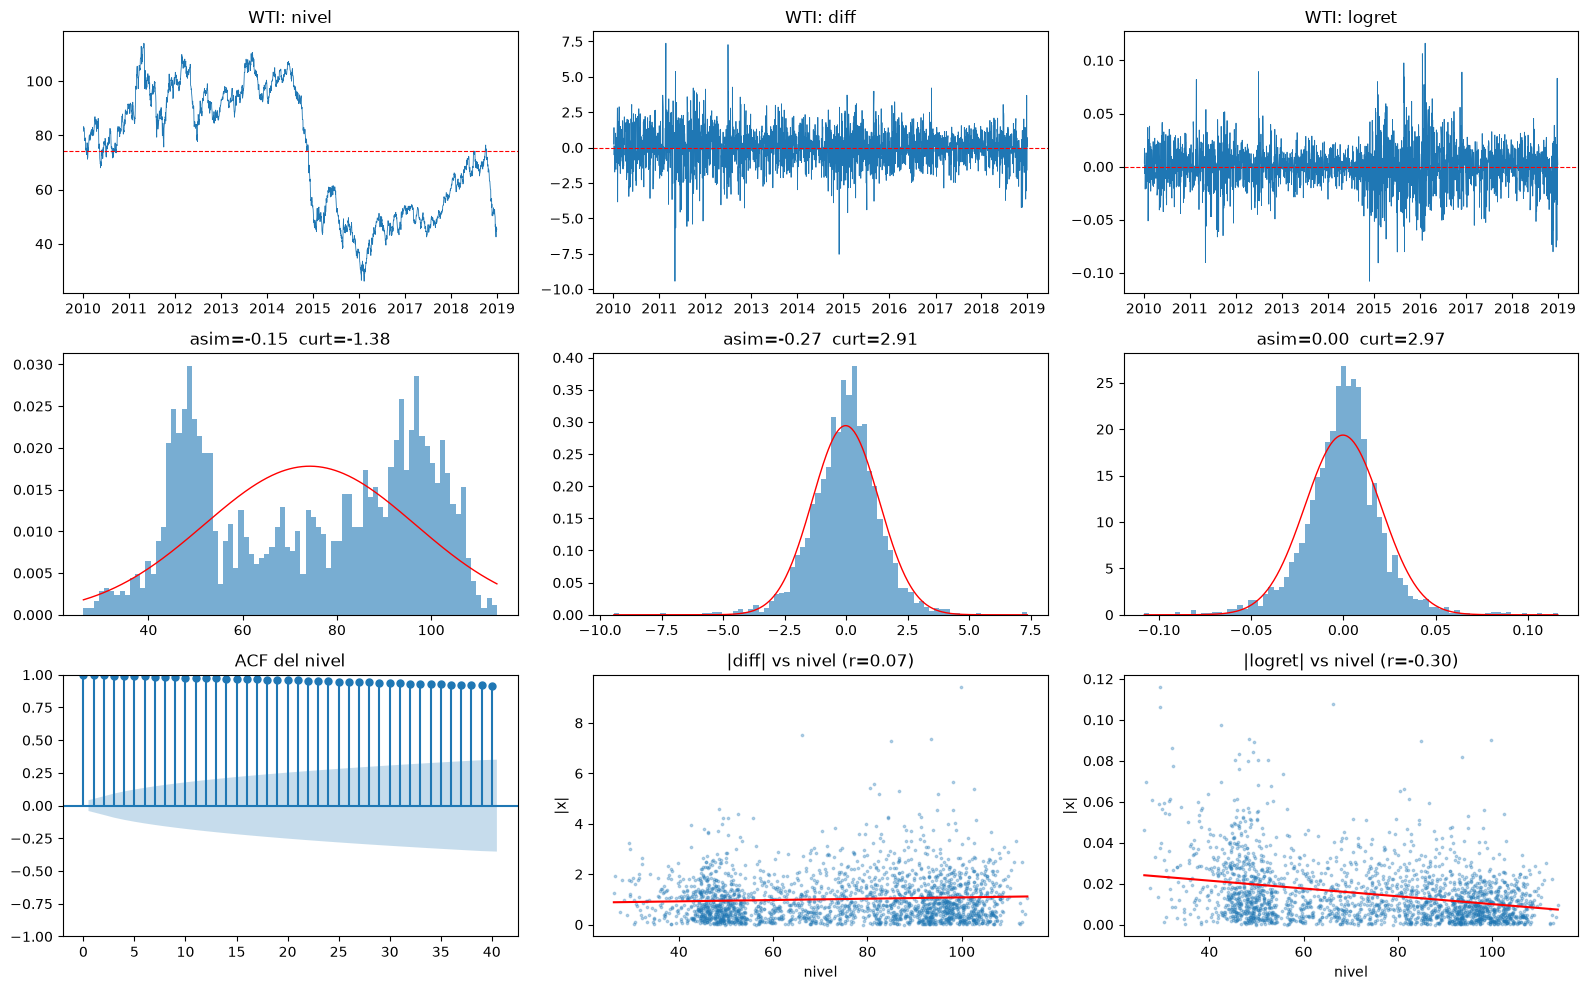

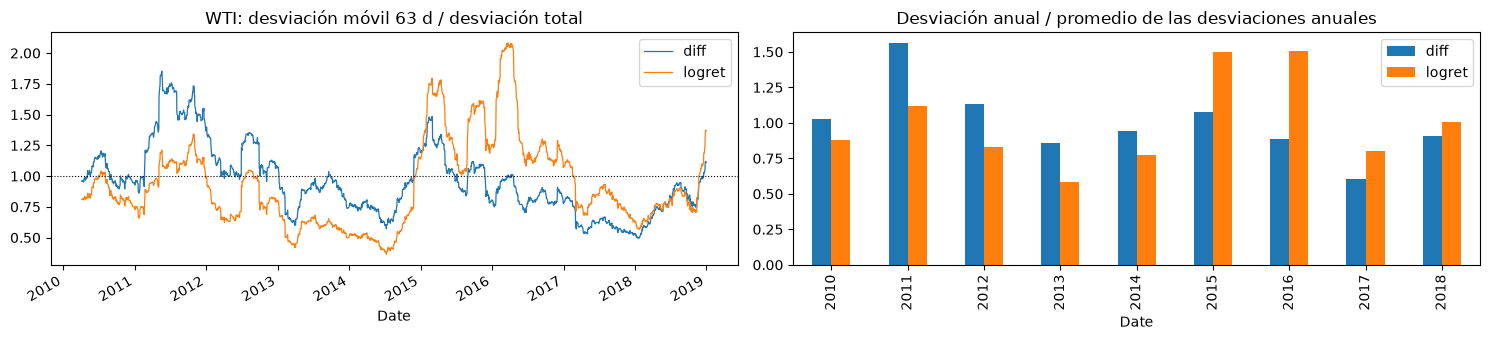

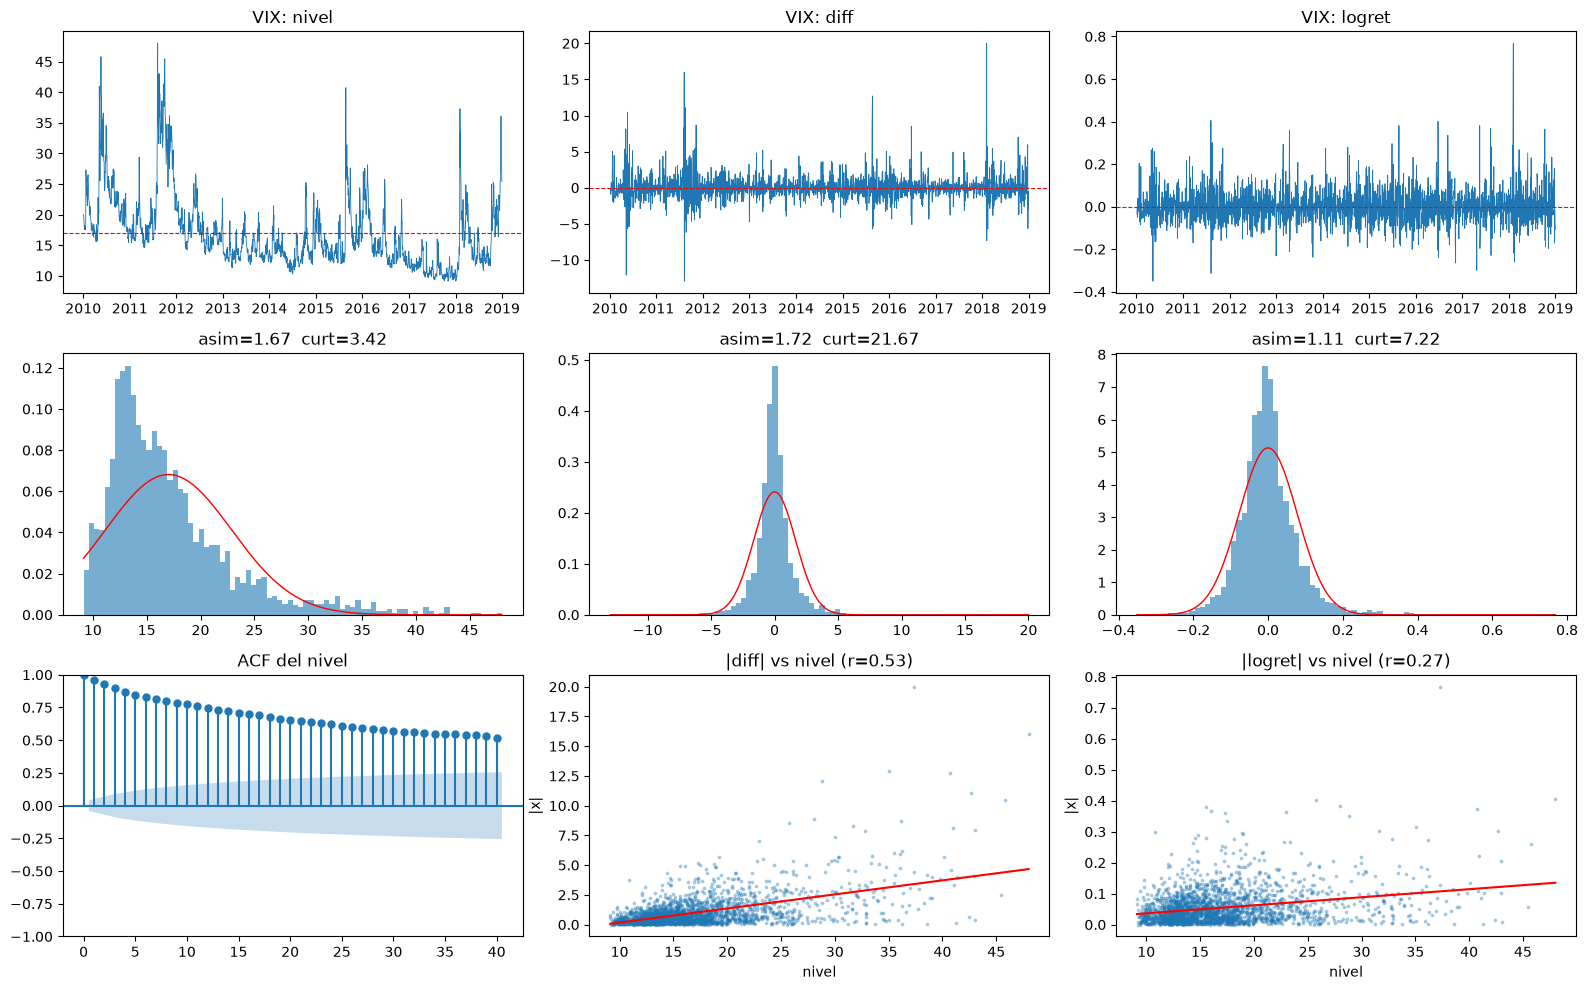

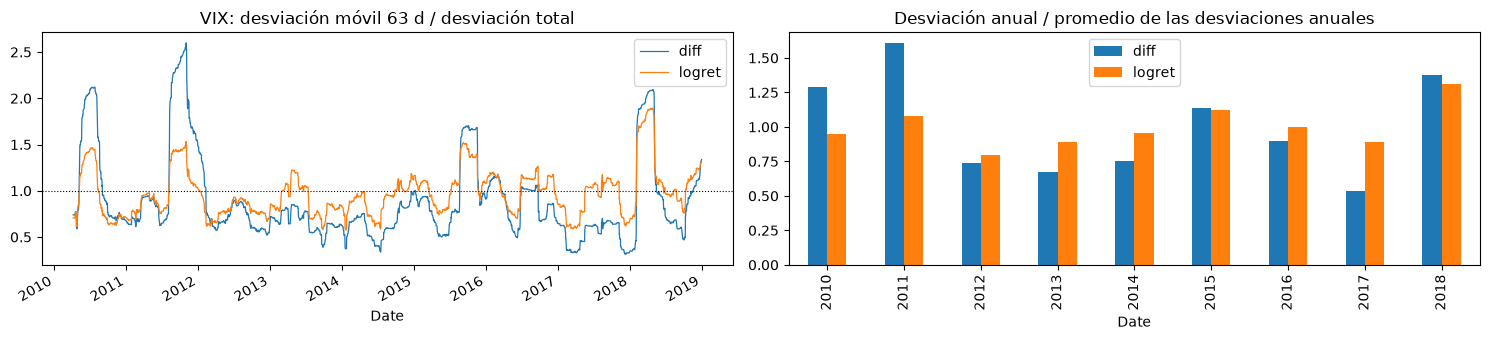

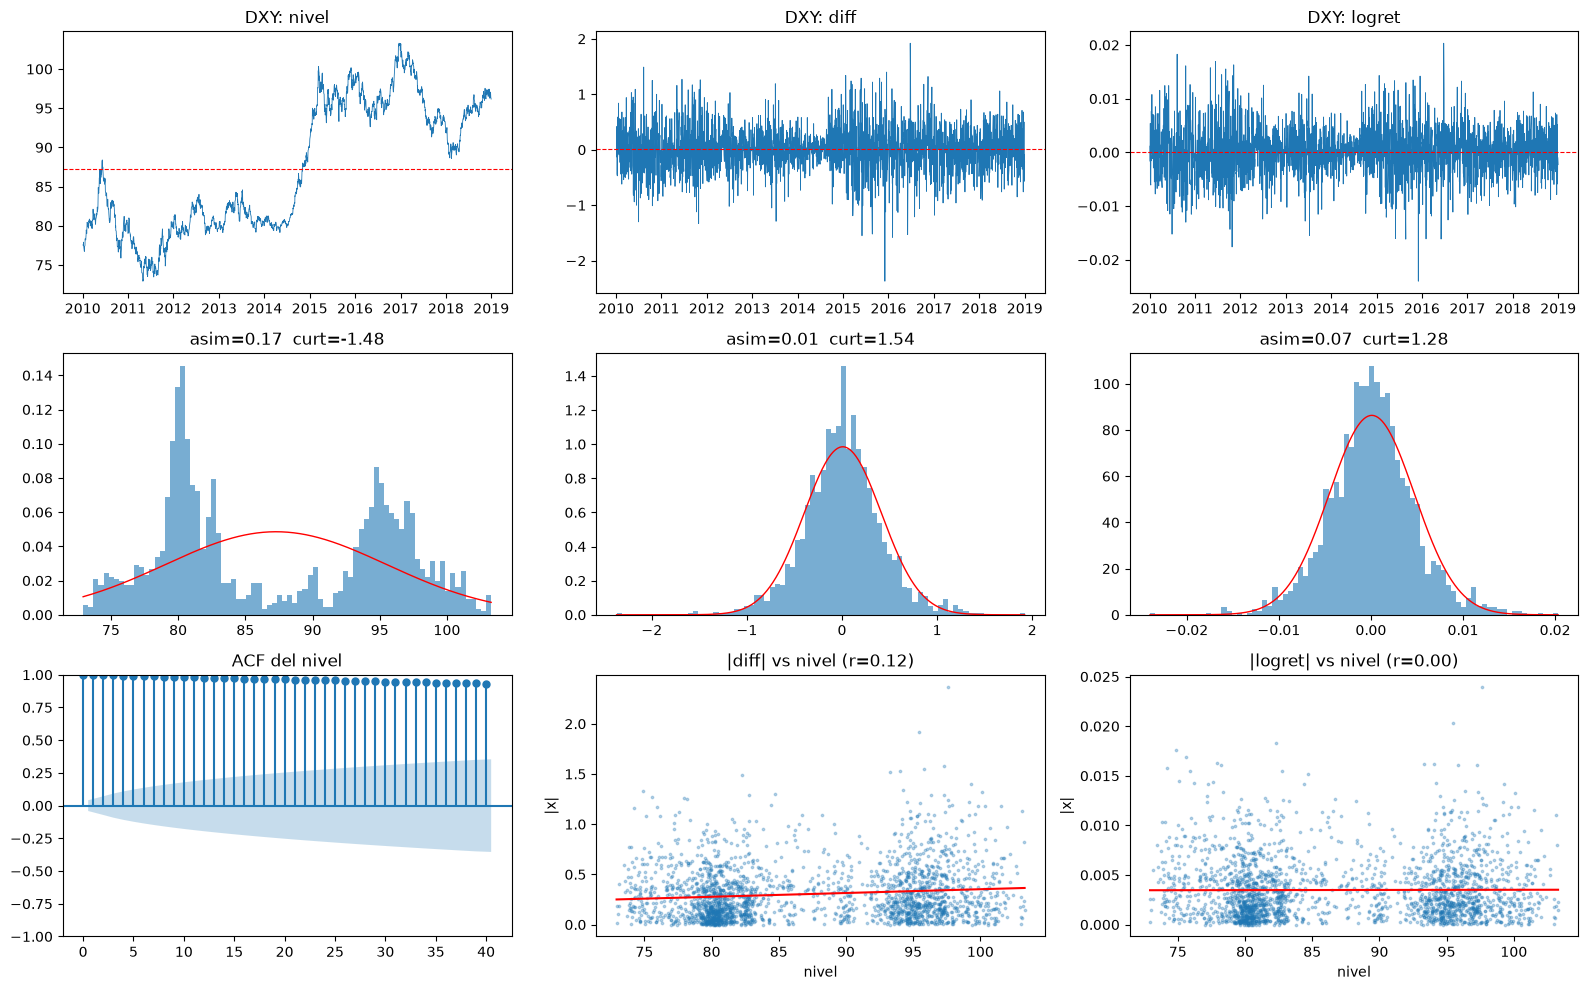

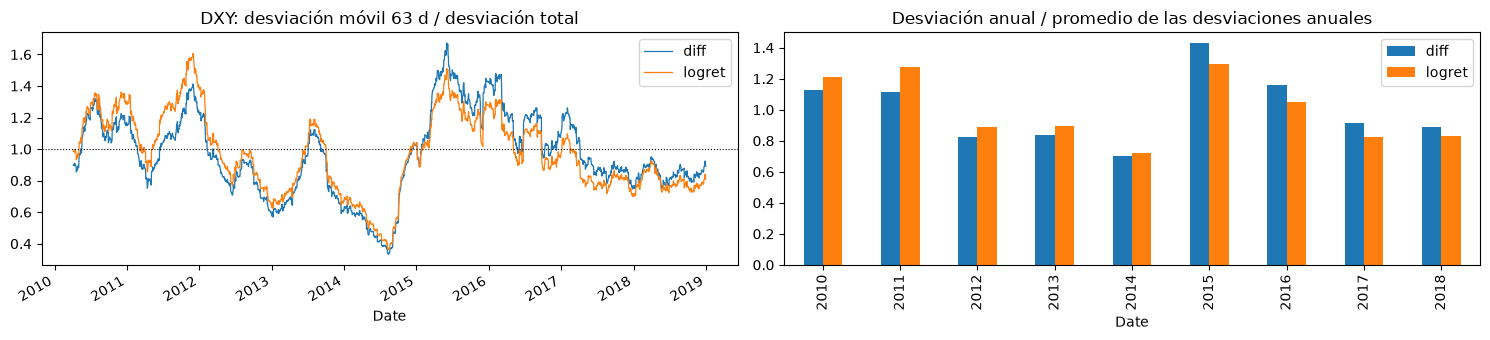

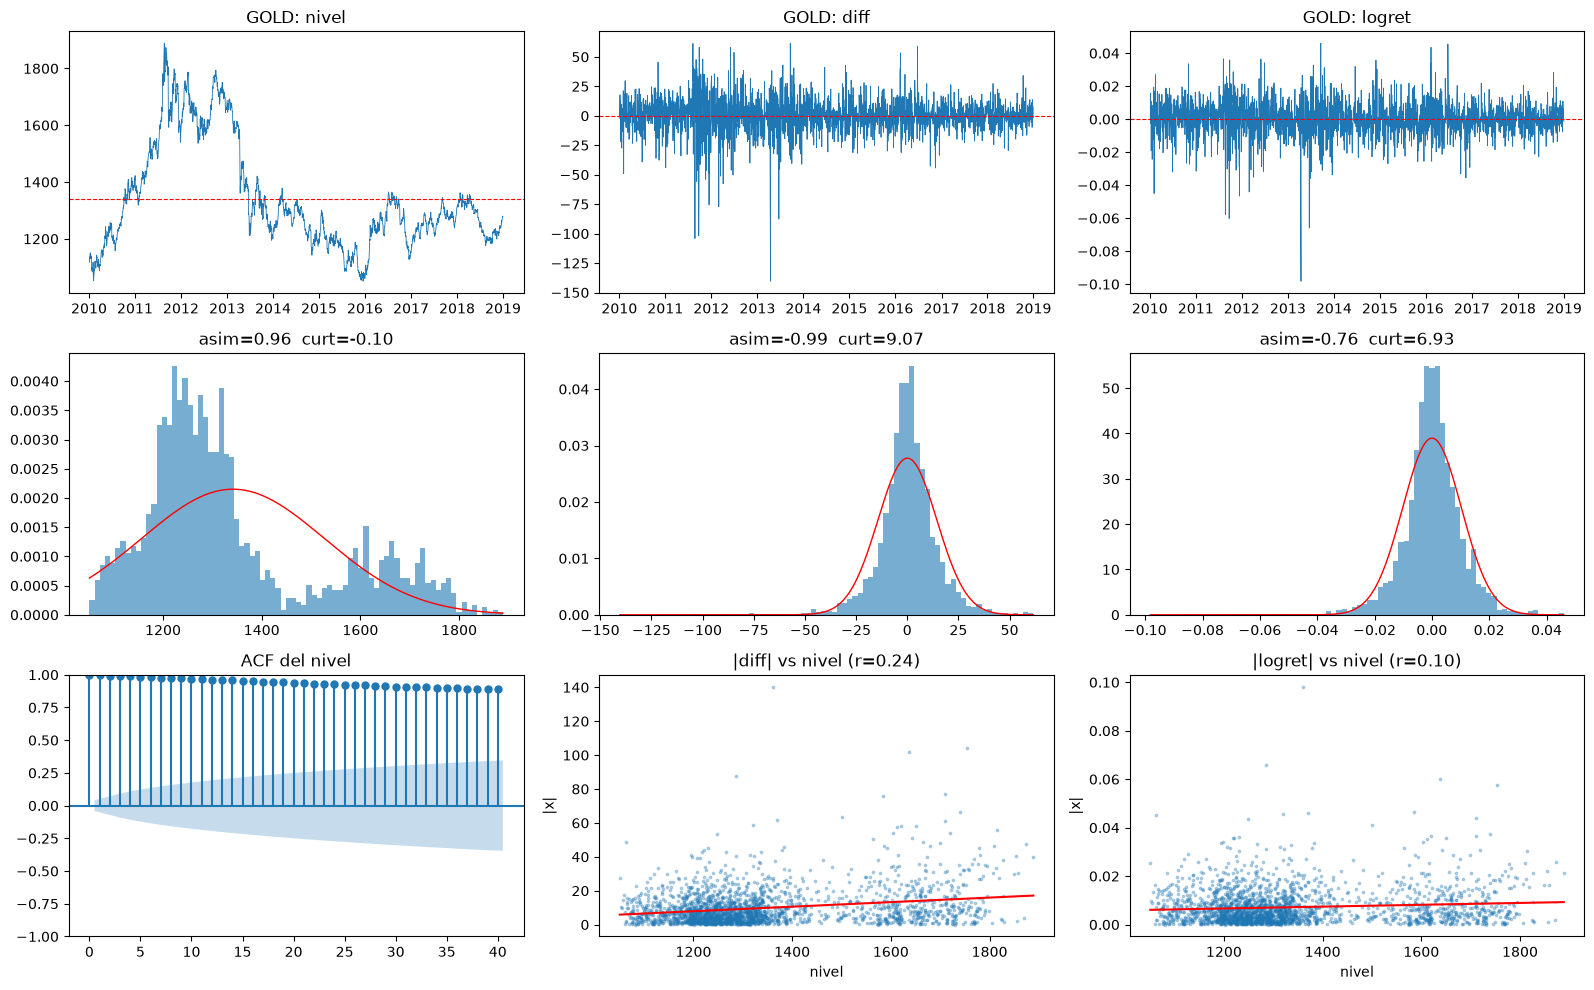

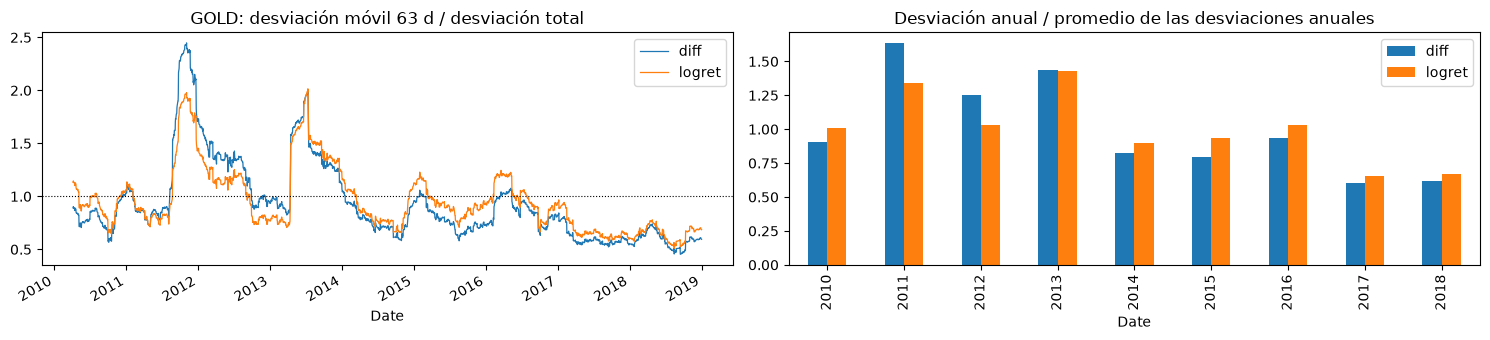

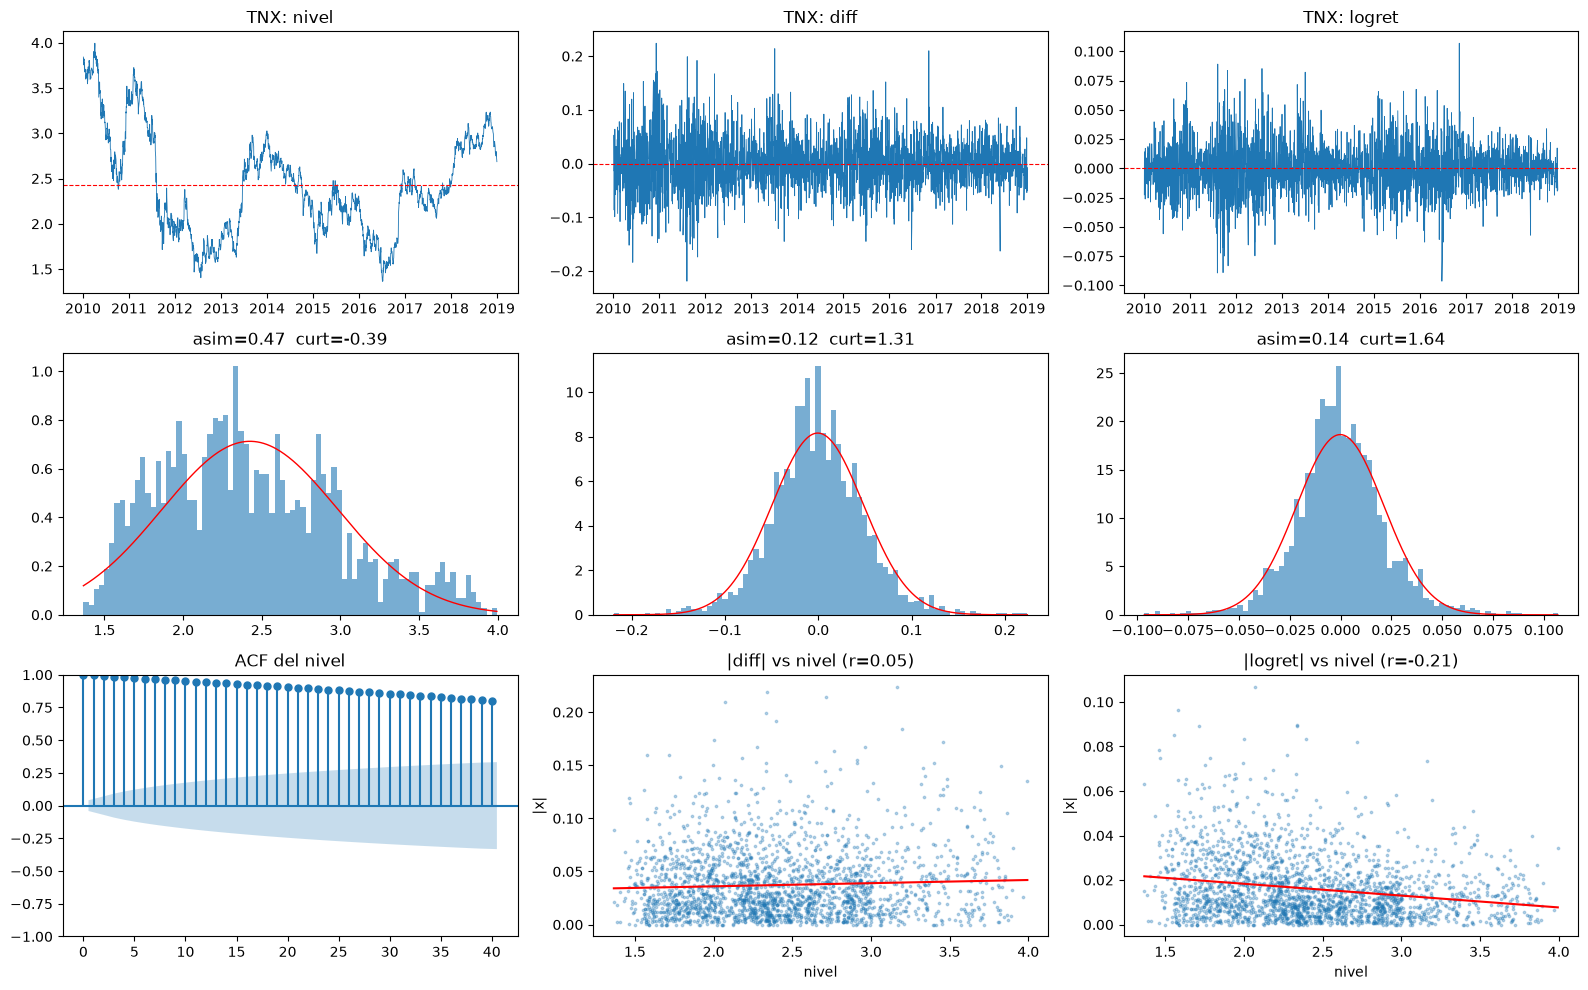

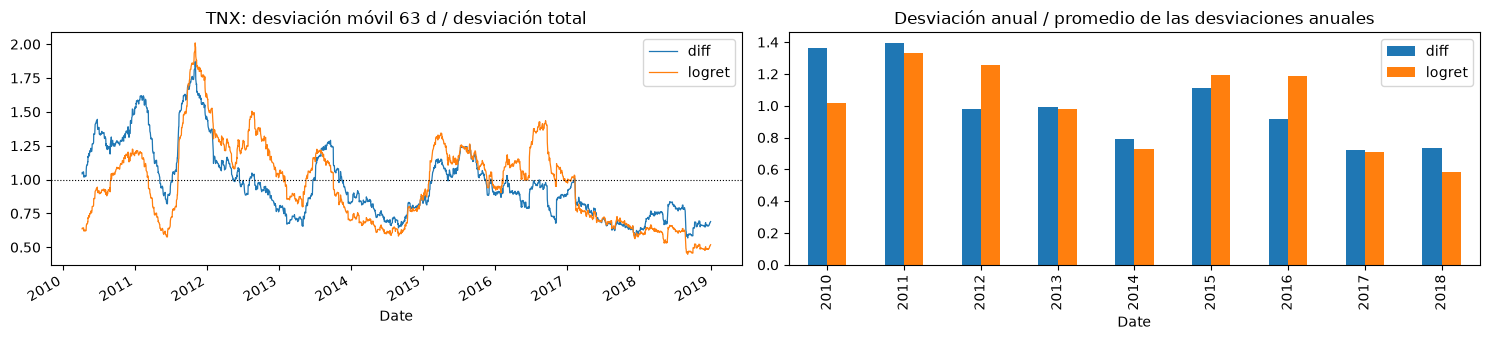

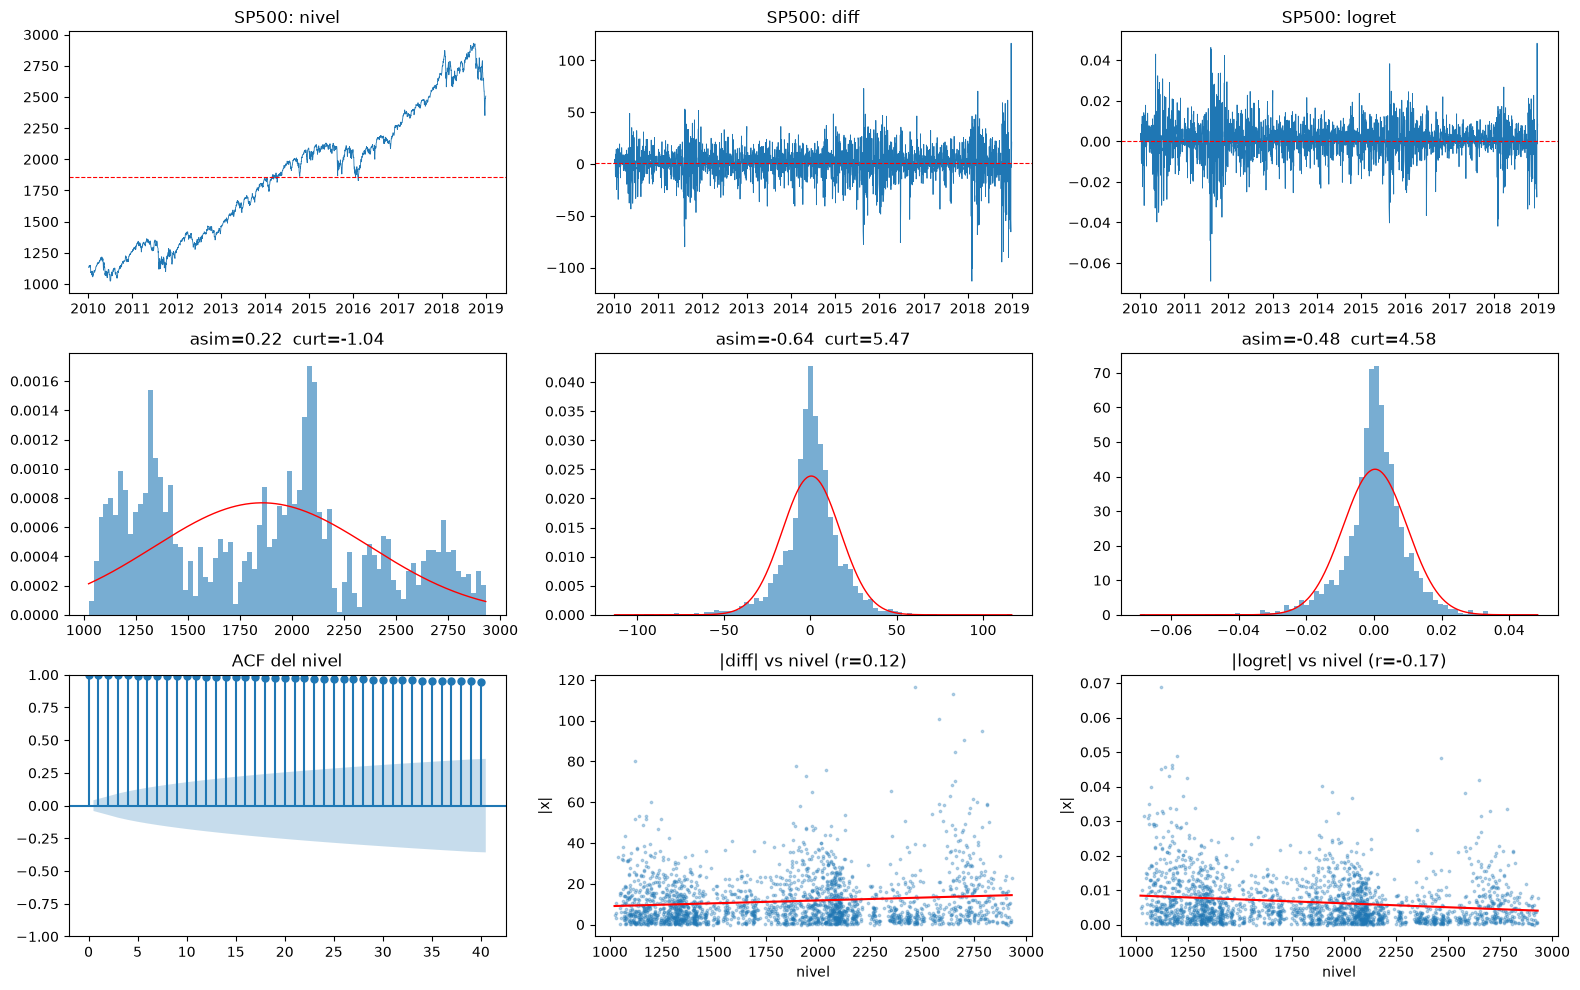

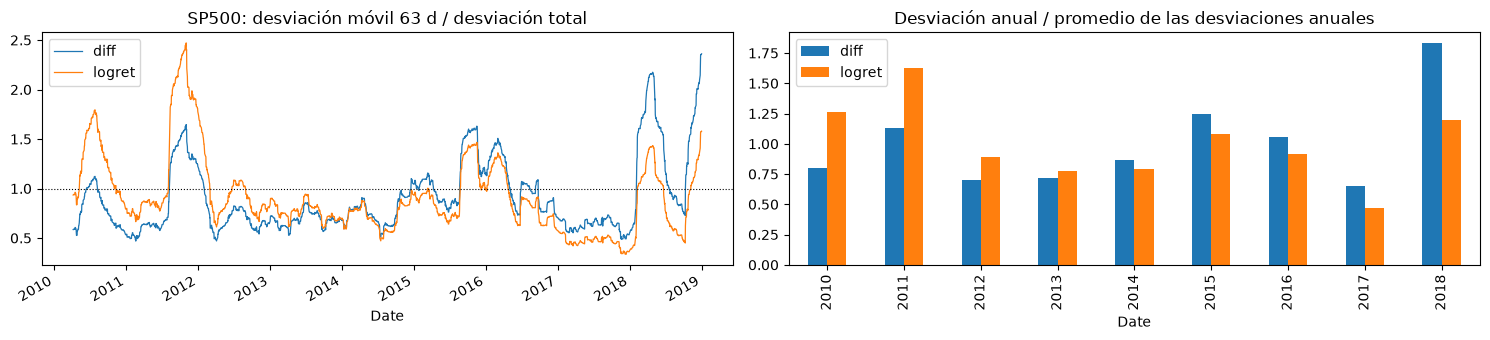

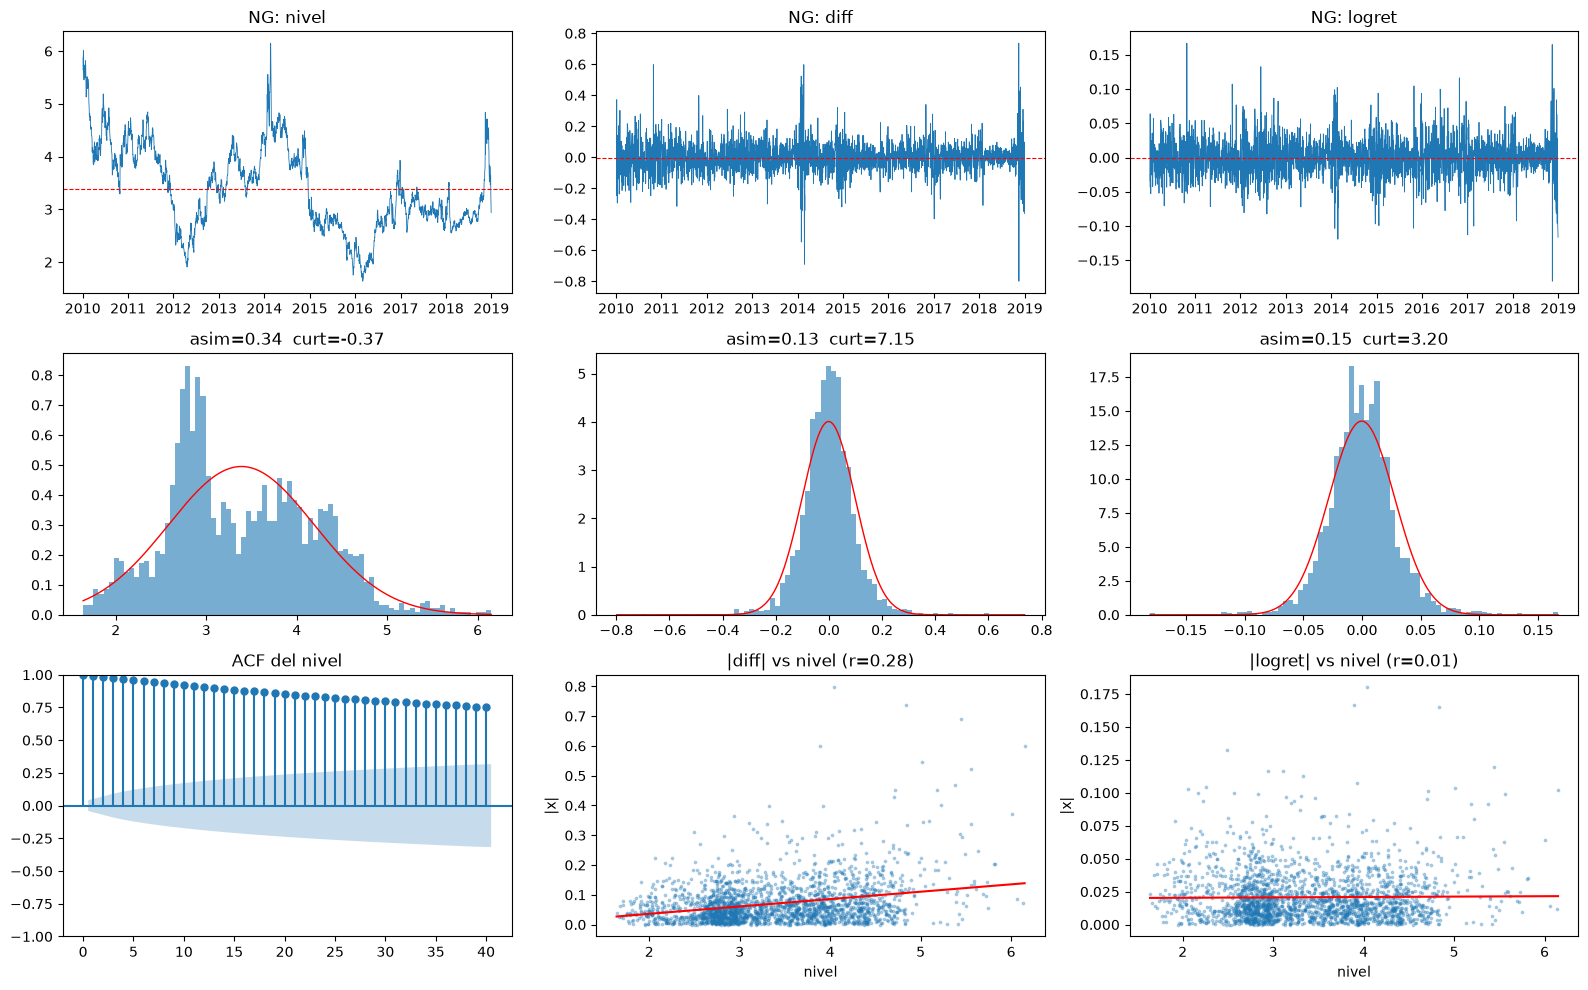

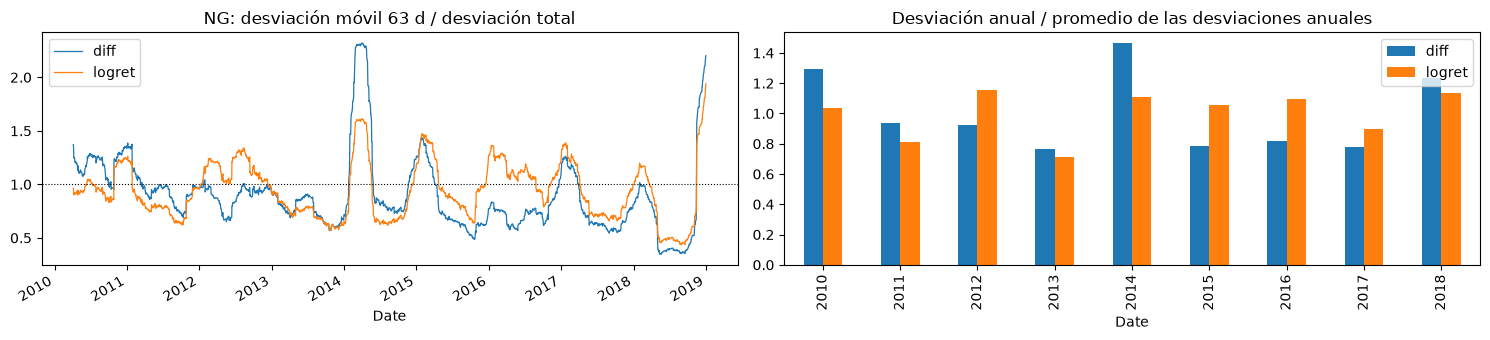

In [38]:
for c in train.columns:
    graficar_transformaciones(c)
    graficar_vol(c)

In [39]:
candidatas = {
    'nivel':  lambda s: s,
    'diff':   lambda s: s.diff(),
    'logret': lambda s: np.log(s).diff(),
}
p = train[c]
filas = []
for c in part['train'].columns:
    for nombre, f in candidatas.items():
        s = f(part['train'][c]).dropna()
        x = part['train'][c].reindex(s.index)       # nivel alineado con s

        adf_stat, adf_p = adfuller(s, autolag='AIC')[:2]

        # Desviación de la transformación en el tercil alto / tercil bajo del nivel
        if nombre != 'nivel':
            terc = pd.qcut(x, 3, labels=False, duplicates='drop')
            sd_t = s.groupby(terc).std()
            ratio = sd_t.iloc[-1] / sd_t.iloc[0]
        else:
            ratio = np.nan                          # no tiene sentido en el nivel
      
        filas.append({
            'serie': c, 'transf': nombre, 'n': len(s),
            'ADF_p': adfuller(s, autolag='AIC')[1], #se determina el p-value del test ADF, menor que 0.05 indica estacionariedad, mayor q 0.05 indica no estacionariedad
            'KPSS_p': kpss(s, regression='c', nlags='auto')[1], #se determina el p-value del test KPSS, menor que 0.05 indica no estacionariedad, mayor q 0.05 indica estacionariedad
            'asimetria': stats.skew(s), # indica la asimetría de la distribución, valores positivos indican asimetría a la derecha y negativos a la izquierda
            'curtosis': stats.kurtosis(s), # indica la curtosis de la distribución, valores mayores a 3 indican colas más pesadas que una distribución normal
            'corr_abs_nivel': s.abs().corr(part['train'][c].reindex(s.index)), # corr_abs_nivel: correlación entre |variación_t| y el nivel del precio_t. 
            #  Mide si el tamaño de los movimientos depende del nivel de la serie: cercano a 0 ( enre -0.1 y 0.1 ) la transformación es adecuada en términos de escala
            # mayor a 0.1 indica que no es adecuada, los movimientos son más grandes  cuando el precio está alto y menor a 0.1 los movimientos son más grandes cuando el precio está bajo.
            'ADF_stat':adfuller(s, autolag='AIC')[0], #se determina el estadístico del test ADF, menor que el valor crítico indica estacionariedad, mayor q el valor crítico indica no estacionariedad
            'spearman_abs_nivel': stats.spearmanr(s.abs(), x)[0], #determina el coeficiente de correlación de Spearman entre |variación_t| y el nivel del precio_t. Mide si el tamaño de los movimientos depende del nivel de la serie: cercano a 0 ( enre -0.1 y 0.1 ) la transformación es adecuada en términos de escala
            'ratio_std_alto_bajo': ratio, #relación entre la desviación estándar por tercil de nivel, cercano a 1 indica que la transformación es adecuada, mayor a 1 o menor a 0,8 no es adecuado.
        })

diag = pd.DataFrame(filas).round(4)
print(diag.to_string(index=False))

serie transf    n  ADF_p  KPSS_p  asimetria  curtosis  corr_abs_nivel  ADF_stat  spearman_abs_nivel  ratio_std_alto_bajo
  WTI  nivel 2260 0.7174    0.01    -0.1540   -1.3778          1.0000   -1.0941              1.0000                  NaN
  WTI   diff 2259 0.0000    0.10    -0.2654    2.9116          0.0651  -49.6979              0.0386               1.1704
  WTI logret 2259 0.0000    0.10     0.0038    2.9703         -0.3016  -33.5338             -0.2748               0.5335
  VIX  nivel 2260 0.0034    0.01     1.6672    3.4210          1.0000   -3.7577              1.0000                  NaN
  VIX   diff 2259 0.0000    0.10     1.7234   21.6653          0.5266  -13.2451              0.4422               3.9182
  VIX logret 2259 0.0000    0.10     1.1126    7.2181          0.2746  -15.4314              0.2281               1.8915
  DXY  nivel 2260 0.6638    0.01     0.1711   -1.4808          1.0000   -1.2226              1.0000                  NaN
  DXY   diff 2259 0.0000    0.10

In [41]:
import statsmodels.api as sm

w = 63
for c in ['WTI', 'SP500']:
    p = part['train'][c]
    vol = p.diff().rolling(w).std().dropna()
    niv = p.rolling(w).mean().reindex(vol.index)
    X = sm.add_constant(np.log(niv))
    m = sm.OLS(np.log(vol), X).fit(cov_type='HAC', cov_kwds={'maxlags': w})   # ventanas solapadas
    print(f"{c}: k = {m.params.iloc[1]:.2f}  (IC95% {m.conf_int().iloc[1, 0]:.2f} a {m.conf_int().iloc[1, 1]:.2f})")

WTI: k = 0.29  (IC95% 0.03 a 0.54)
SP500: k = 0.34  (IC95% -0.06 a 0.74)


In [42]:
for c in ['WTI', 'SP500']:
    p = part['train'][c]
    for w in (21, 63, 126):
        vol = p.diff().rolling(w).std().dropna()
        niv = p.rolling(w).mean().reindex(vol.index)
        m = sm.OLS(np.log(vol), sm.add_constant(np.log(niv))).fit(cov_type='HAC', cov_kwds={'maxlags': w})
        lo, hi = m.conf_int().iloc[1]
        print(f"{c:6s} w={w:3d}  k={m.params.iloc[1]:.2f}  (IC95% {lo:.2f} a {hi:.2f})")

WTI    w= 21  k=0.25  (IC95% 0.07 a 0.42)
WTI    w= 63  k=0.29  (IC95% 0.03 a 0.54)
WTI    w=126  k=0.33  (IC95% -0.00 a 0.66)
SP500  w= 21  k=0.34  (IC95% 0.04 a 0.64)
SP500  w= 63  k=0.34  (IC95% -0.06 a 0.74)
SP500  w=126  k=0.37  (IC95% -0.09 a 0.83)


1. Las series en nivel no son representativas y deben transformarse.
WTI (ADF p = 0,72), DXY (0,66), GOLD (0,31) y SP500 (0,79) no rechazan la raíz unitaria, y TNX queda en el límite (0,055). VIX (0,003) y NG (0,009) sí rechazan en ADF, pero en las siete series KPSS rechaza la estacionariedad (p ≤ 0,01). En VIX y NG esa contradicción indica series muy persistentes, no estacionarias. Además, la curtosis negativa en WTI (-1,38), DXY (-1,48) y SP500 (-1,04) refleja distribuciones aplanadas por tendencias y regímenes de nivel, no el comportamiento de colas pesadas que quieres modelar. Por eso las series en nivel no sirven como insumo de los modelos.

2. Con diff, las series que quedan con mejor escala son WTI y TNX.
Su corr_abs_nivel es 0,065 (WTI) y 0,053 (TNX), y Spearman confirma (0,039 y 0,029), es decir, el tamaño del cambio en puntos no depende del nivel. SP500 (0,119) y DXY (0,116) quedan en el límite del rango de ±0,1. En cambio, diff funciona mal en VIX (0,53), NG (0,28) y GOLD (0,24), donde los cambios crecen con el nivel, y además deja colas muy pesadas (curtosis de 21,7 en VIX, 9,1 en GOLD y 7,1 en NG). Todas las series diferenciadas son estacionarias (ADF p ≈ 0, KPSS p ≥ 0,10).

3. Con logret, mejoran VIX, NG, DXY y GOLD.

NG pasa de 0,28 a 0,013 y su curtosis de 7,1 a 3,2.
DXY queda en 0,005.
GOLD baja a 0,097 (dentro del rango) y su curtosis de 9,1 a 6,9.
VIX mejora de forma clara (0,53 → 0,27; curtosis 21,7 → 7,2), pero conserva dependencia del nivel: su volatilidad sube cuando el VIX está alto, y es una característica real de la serie.
SP500 es un empate técnico (diff 0,12 vs logret -0,17). Prefiero logret por menor asimetría y curtosis (4,6 vs 5,5) y por convención. El signo negativo suele reflejar el efecto apalancamiento.
TNX empeora con logret (-0,21), por eso se mantiene en diff, además de ser una tasa de interés.

4. El caso del WTI.
Por escala, diff obtiene mejores resultados en los cuatro criterios: corr_abs_nivel (0,065 vs -0,30 con logret), Spearman (0,039 vs -0,27), ratio_std_alto_bajo (1,17 vs 0,53) y elasticidad de la volatilidad respecto al nivel (k = 0,25-0,33 en ventanas de 21, 63 y 126 días; el límite superior de los intervalos nunca se acerca a 1). Esto indica que la variación del WTI es aproximadamente estable en dólares y no proporcional al nivel, por lo que con logret los movimientos porcentuales son mayores cuando el precio está bajo (por ejemplo, 2015-2016). Esta evidencia mezcla escala y régimen de volatilidad: la mayor volatilidad porcentual con precios bajos puede ser un rasgo real de la serie que los modelos deben capturar, y no solo un artefacto de la transformación. Por ello se presenta como orientativa y no descarta logret. Se adopta logret para el WTI por las siguientes razones:

- Es la variable objetivo definida en la propuesta y la transformación estándar en la literatura de modelos GARCH, TimeGAN y de riesgo, lo que permite comparar los resultados con los trabajos citados.
- Es estacionaria (ADF p ≈ 0, KPSS p ≥ 0,10) y su distribución es simétrica (asimetría = 0,004 frente a -0,27 de diff), con curtosis similar (2,97 vs 2,91).
- Expresa las variaciones en porcentaje, lo que permite comparar movimientos entre precios de 100 y de 20 dólares, y expresa el VaR y el ES (Value at Risk y Expected Shortfall) en porcentaje, comparables entre épocas.

Como limitaciones, logret conserva una dependencia residual del nivel (corr_abs_nivel = -0,30; ratio_std_alto_bajo = 0,53), y no está definido para precios no positivos: el precio de -37,63 USD del 20/04/2020 no admite logaritmo, por lo que ese día y el siguiente quedan sin retorno y se excluyen de las métricas diarias, y las trayectorias generadas son positivas por construcción. Para no perder el punto más extremo del evento, se evalúa de forma complementaria el retorno acumulado entre el 17/04/2020 y el 21/04/2020, ambos con precio positivo. Como análisis de sensibilidad se repite la evaluación con diff.

In [43]:
# Transformación fijada con el diagnóstico en train
TRANSF = {
    'WTI':   'logret',   # precio <= 0 el 20/04/2020 queda en NaN (regla fijada)
    'VIX':   'logret',
    'DXY':   'logret',
    'GOLD':  'logret',
    'SP500': 'logret',
    'NG':    'logret',
    'TNX':   'diff',     # tasa de interés
}

In [44]:
# 1. Transformar sobre toda la serie (es punto a punto, no hay fuga)
rets = pd.DataFrame(index=base1.index)
for c, t in TRANSF.items():
    s = base1[c]
    if t == 'logret':
        rets[c] = np.log(s.where(s > 0)).diff()   # precios <= 0 quedan en NaN
    else:
        rets[c] = s.diff()

In [45]:
rets = rets.iloc[1:]   # el primer día no tiene retorno (queda 2010-01-05 en adelante)

# 2. Misma partición que ya definiste
rets_part = {k: rets.loc[a:b] for k, (a, b) in splits.items()}
rets_ventanas = {k: rets.loc[a:b] for k, (a, b) in ventanas_test.items()}
rets_trainval = rets.loc[:splits['val'][1]]   # solo para el ajuste final del COVID

In [46]:
# 3. Verificaciones
for k, v in rets_part.items():
    print(f"{k:6s} {v.index.min().date()} -> {v.index.max().date()}  n={len(v)}  nulos={v.isna().sum().to_dict()}")

print("infinitos:", np.isinf(rets).sum().sum())
print("fechas con NaN en WTI:", [d.date() for d in rets.index[rets['WTI'].isna()]])

assert rets_part['train'].isna().sum().sum() == 0
assert rets_part['val'].isna().sum().sum() == 0
assert rets_part['test'].isna().sum().sum() == 2          # solo WTI: 20/04 y 21/04/2020
assert sum(len(v) for v in rets_ventanas.values()) == len(rets_part['test'])

# 4. Retorno acumulado a través del hueco del 20-21/04/2020 (evaluación complementaria)
acum_hueco = np.log(base1.loc['2020-04-21', 'WTI']) - np.log(base1.loc['2020-04-17', 'WTI'])
print(f"log-retorno acumulado WTI 17/04 -> 21/04/2020: {acum_hueco:.4f}")

train  2010-01-05 -> 2018-12-31  n=2259  nulos={'WTI': 0, 'VIX': 0, 'DXY': 0, 'GOLD': 0, 'SP500': 0, 'NG': 0, 'TNX': 0}
val    2019-01-02 -> 2019-12-31  n=252  nulos={'WTI': 0, 'VIX': 0, 'DXY': 0, 'GOLD': 0, 'SP500': 0, 'NG': 0, 'TNX': 0}
test   2020-01-02 -> 2026-10-20  n=1709  nulos={'WTI': 2, 'VIX': 0, 'DXY': 0, 'GOLD': 0, 'SP500': 0, 'NG': 0, 'TNX': 0}
infinitos: 0
fechas con NaN en WTI: [datetime.date(2020, 4, 20), datetime.date(2020, 4, 21)]
log-retorno acumulado WTI 17/04 -> 21/04/2020: -0.6017


In [47]:
def estadisticos(serie, nombre=None, lags=10):
    """Estadísticos descriptivos y pruebas para una serie ya transformada (retornos o diferencias)."""
    r = serie.dropna()
    nombre = nombre or serie.name

    with warnings.catch_warnings():
        warnings.simplefilter('ignore')   # KPSS lanza InterpolationWarning en los extremos
        adf_stat, adf_p = adfuller(r, autolag='AIC')[:2]
        kpss_stat, kpss_p = kpss(r, regression='c', nlags='auto')[:2]

    jb_stat, jb_p = stats.jarque_bera(r)
    gl_t, loc_t, esc_t = stats.t.fit(r)
    lb_r  = acorr_ljungbox(r,    lags=[lags])
    lb_r2 = acorr_ljungbox(r**2, lags=[lags])
    lm_stat, lm_p, _, _ = het_arch(r, nlags=lags)

    res = {
        # Descriptivos
        'n': len(r),
        'media': r.mean(),
        'std': r.std(),
        'min': r.min(),
        'p01': r.quantile(0.01),
        'p05': r.quantile(0.05),
        'mediana': r.median(),
        'p95': r.quantile(0.95),
        'p99': r.quantile(0.99),
        'max': r.max(),
        'asimetria': stats.skew(r),
        'curtosis_exceso': stats.kurtosis(r),
        # Normalidad y colas
        'JB_stat': jb_stat, 'JB_p': jb_p,
        't_gl': gl_t,
        # Estacionariedad
        'ADF_stat': adf_stat, 'ADF_p': adf_p,
        'KPSS_stat': kpss_stat, 'KPSS_p': kpss_p,
        # Dependencia temporal
        f'LB_r_p({lags})': lb_r['lb_pvalue'].iloc[0],
        f'LB_r2_p({lags})': lb_r2['lb_pvalue'].iloc[0],
        f'ARCH_LM_p({lags})': lm_p,
        'autocorr_r_lag1': r.autocorr(1),
        'autocorr_r2_lag1': (r**2).autocorr(1),
        # Apalancamiento: correlación entre r(t-1) y |r(t)|
        'apalancamiento': r.shift(1).corr(r.abs()),
        # Riesgo extremo empírico (pérdidas)
        'VaR_1%': -r.quantile(0.01),
        'VaR_5%': -r.quantile(0.05),
        'ES_1%': -r[r <= r.quantile(0.01)].mean(),
        'ES_5%': -r[r <= r.quantile(0.05)].mean(),
    }
    return pd.Series(res, name=nombre)

In [48]:
tabla_train = pd.concat(
    [estadisticos(rets_part['train'][c], c) for c in rets.columns], axis=1
)

In [49]:
tabla_train

,WTI,VIX,DXY,GOLD,SP500,NG,TNX
n,2.259000e+03,2.259000e+03,2.259000e+03,2.259000e+03,2.259000e+03,2.259000e+03,2.259000e+03
media,-2.589612e-04,1.052705e-04,9.537516e-05,5.943256e-05,3.515568e-04,-3.071391e-04,-5.112882e-04
std,2.060719e-02,7.779361e-02,4.621997e-03,1.023817e-02,9.473497e-03,2.799006e-02,4.889678e-02
min,-1.079422e-01,-3.505885e-01,-2.398774e-02,-9.820579e-02,-6.895837e-02,-1.805451e-01,-2.190001e-01
p01,-5.672344e-02,-1.787090e-01,-1.122824e-02,-2.898921e-02,-2.870109e-02,-6.959076e-02,-1.254200e-01
p05,-3.405750e-02,-1.085707e-01,-7.432891e-03,-1.633866e-02,-1.590818e-02,-4.280275e-02,-7.710011e-02
mediana,3.635598e-04,-5.189018e-03,1.057451e-04,1.535244e-04,5.379447e-04,-5.125815e-04,-2.000093e-03
p95,3.027631e-02,1.255112e-01,7.704681e-03,1.573041e-02,1.433769e-02,4.412846e-02,7.900000e-02
p99,5.399519e-02,2.555807e-01,1.243570e-02,2.517806e-02,2.419684e-02,7.752249e-02,1.252600e-01
max,1.162133e-01,7.682450e-01,2.032029e-02,4.602633e-02,4.840318e-02,1.669139e-01,2.240000e-01


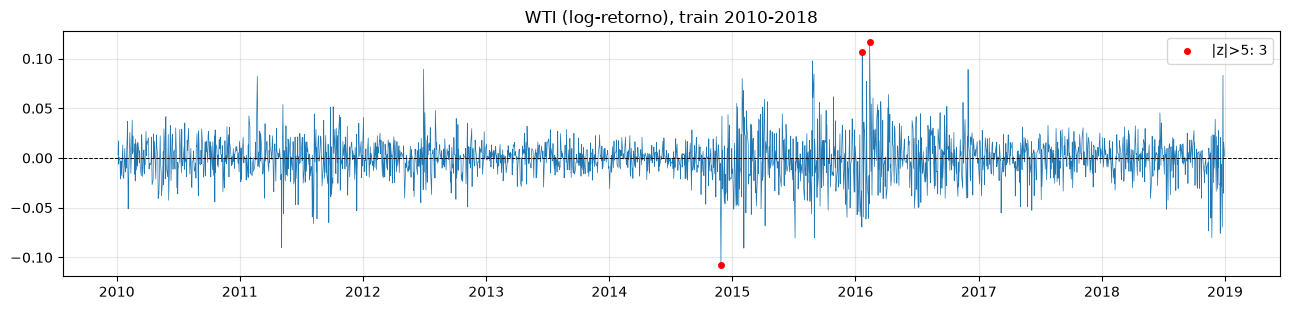

WTI {datetime.date(2014, 11, 28): -0.1079, datetime.date(2016, 1, 21): 0.1064, datetime.date(2016, 2, 12): 0.1162}


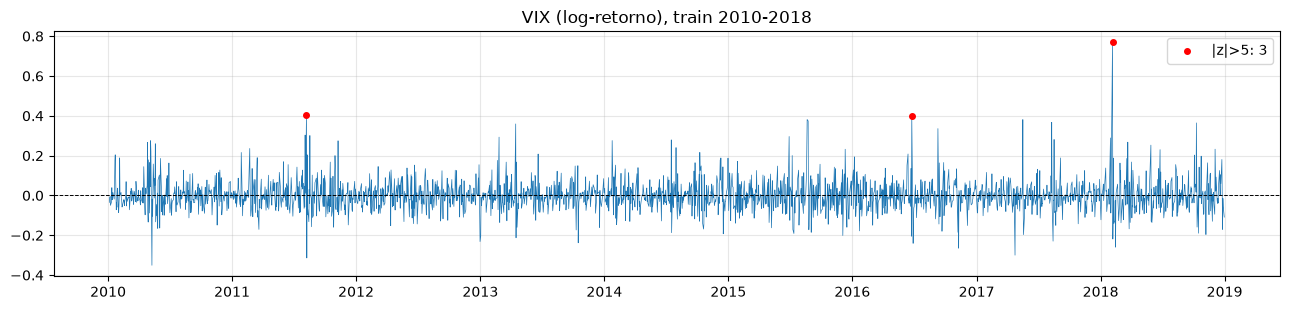

VIX {datetime.date(2011, 8, 8): 0.4055, datetime.date(2016, 6, 24): 0.401, datetime.date(2018, 2, 5): 0.7682}


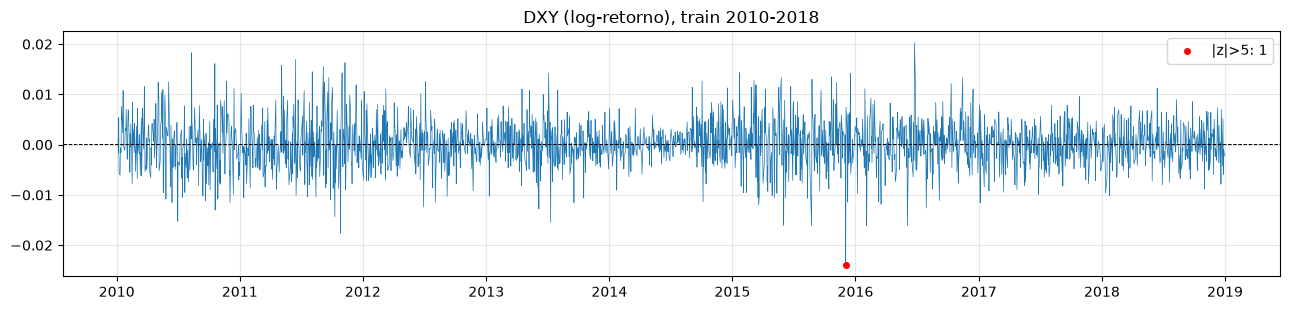

DXY {datetime.date(2015, 12, 3): -0.024}


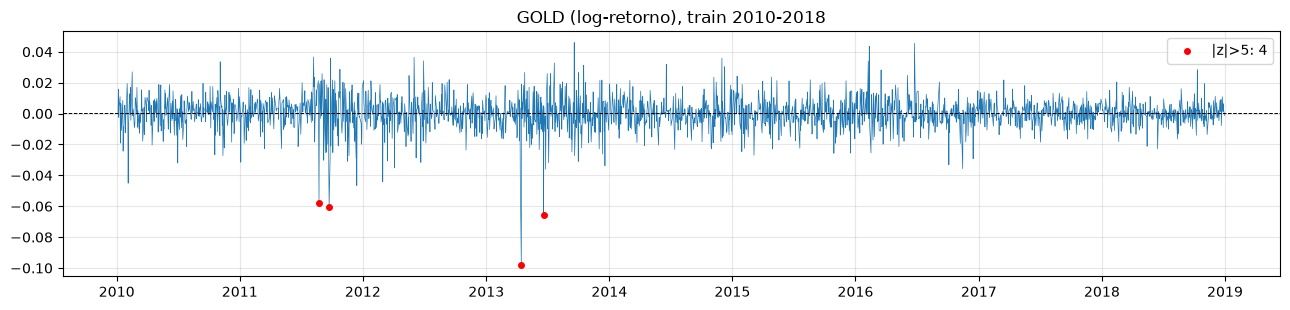

GOLD {datetime.date(2011, 8, 24): -0.0577, datetime.date(2011, 9, 23): -0.0603, datetime.date(2013, 4, 15): -0.0982, datetime.date(2013, 6, 20): -0.066}


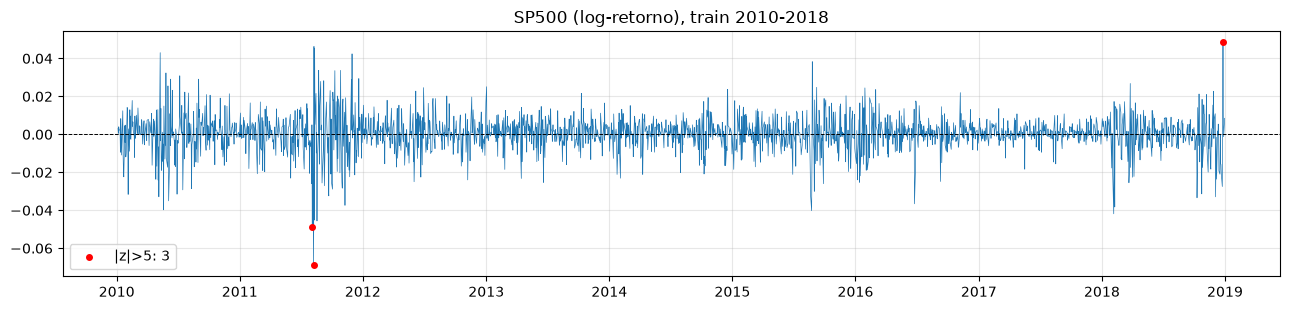

SP500 {datetime.date(2011, 8, 4): -0.049, datetime.date(2011, 8, 8): -0.069, datetime.date(2018, 12, 26): 0.0484}


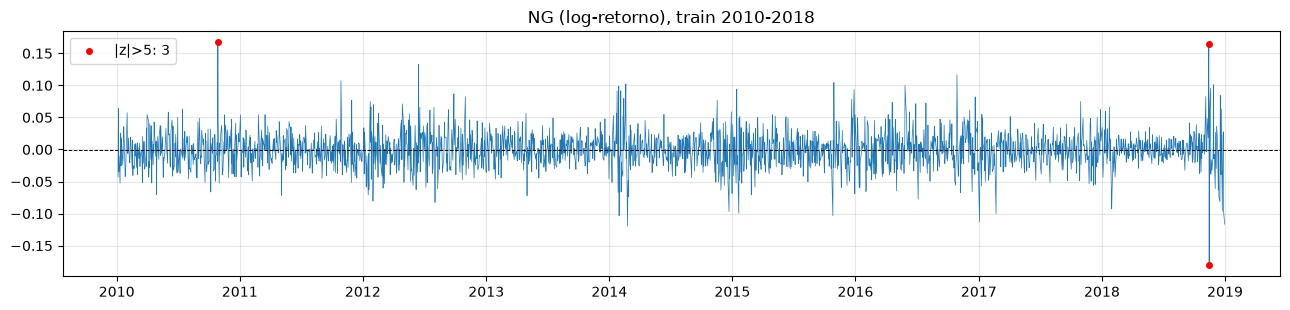

NG {datetime.date(2010, 10, 28): 0.1669, datetime.date(2018, 11, 14): 0.1651, datetime.date(2018, 11, 15): -0.1805}


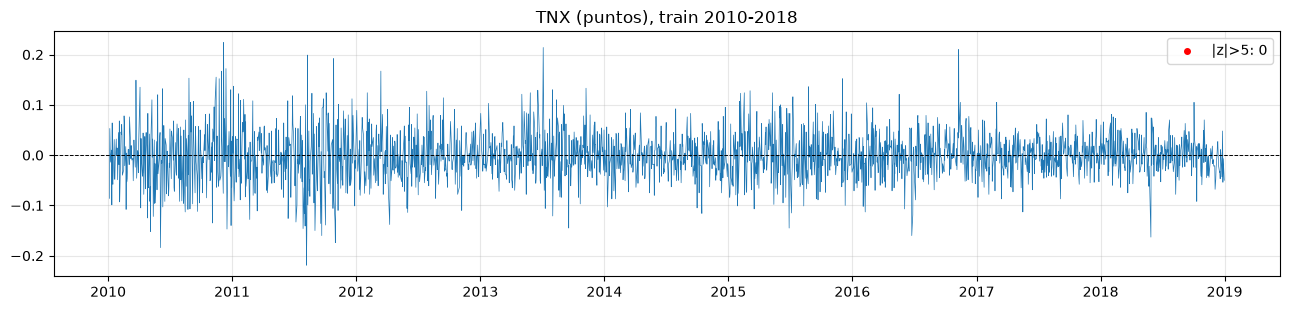

In [51]:
tr = rets_part['train']
UNID = {c: ('puntos' if TRANSF[c] == 'diff' else 'log-retorno') for c in tr.columns}

def graficar_serie(c, k=5):
    r = tr[c].dropna()
    mu, sd = r.mean(), r.std()                 # sigma de train
    out = r[(r - mu).abs() > k * sd]

    fig, ax = plt.subplots(figsize=(13, 3.2))
    ax.plot(r, lw=0.5)
    ax.axhline(mu, color='k', ls='--', lw=0.7)
    ax.scatter(out.index, out, color='red', s=16, zorder=3, label=f'|z|>{k}: {len(out)}')
    ax.set_title(f'{c} ({UNID[c]}), train 2010-2018')
    ax.grid(alpha=0.3); ax.legend()
    plt.tight_layout(); plt.show()

    if len(out):
        print(c, {d.date(): round(v, 4) for d, v in out.items()})

for c in tr.columns:
    graficar_serie(c)

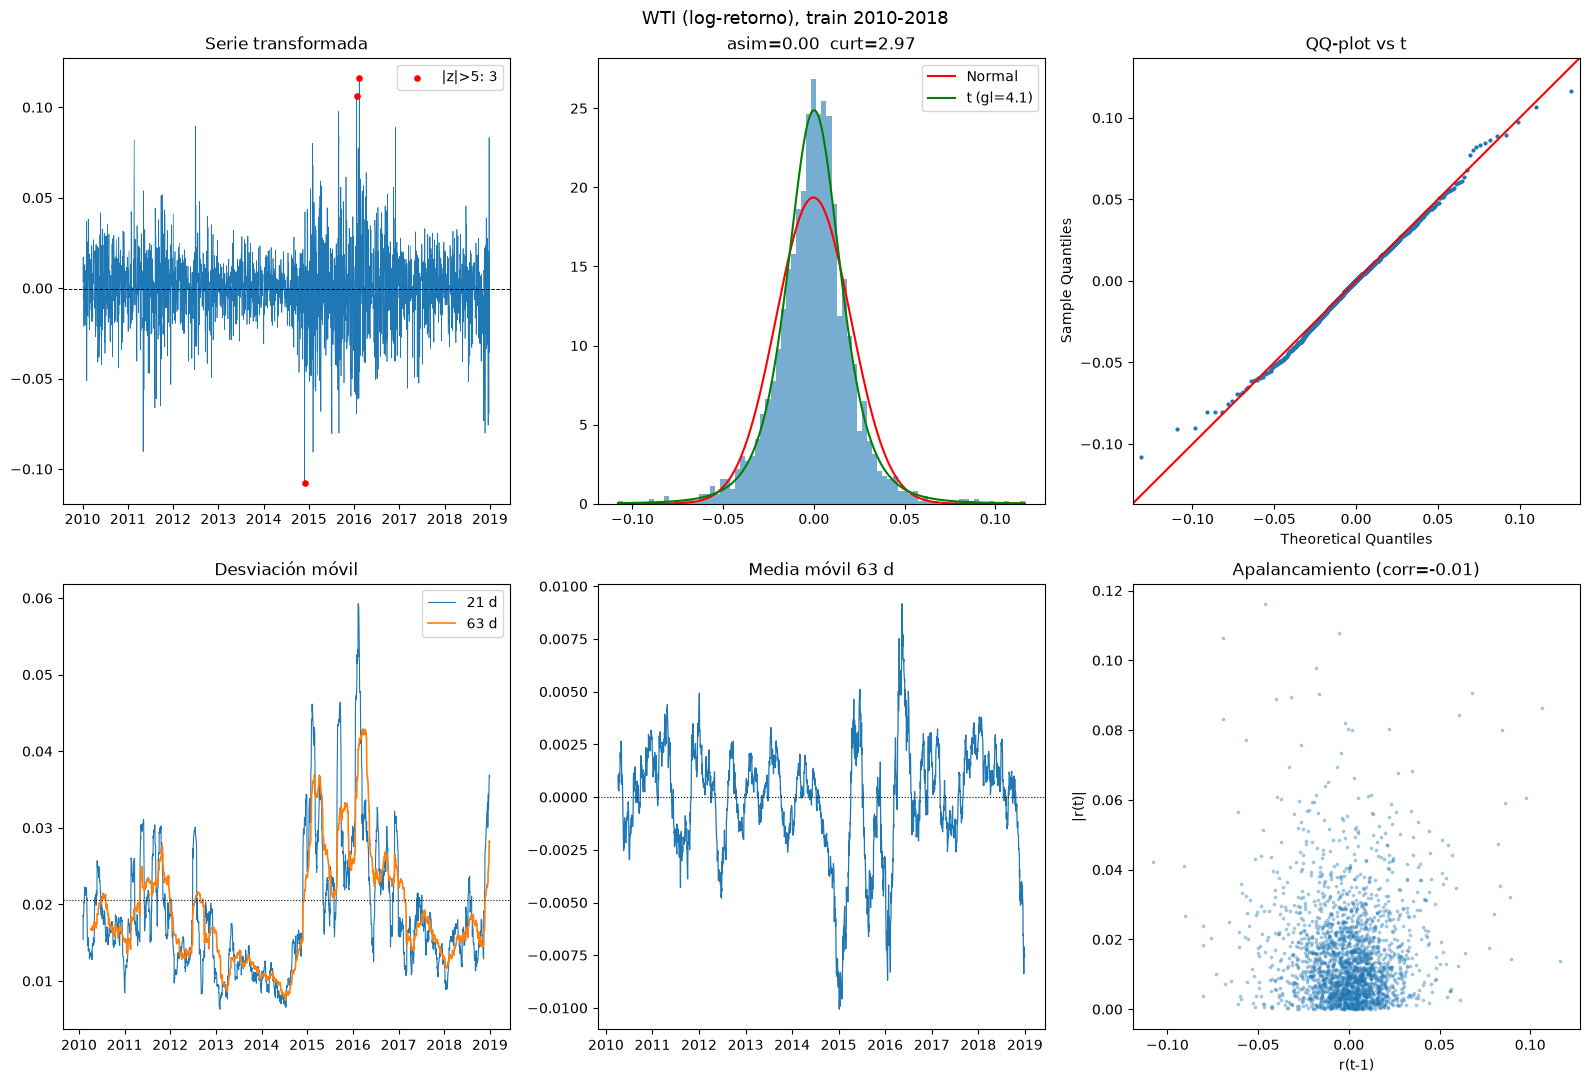

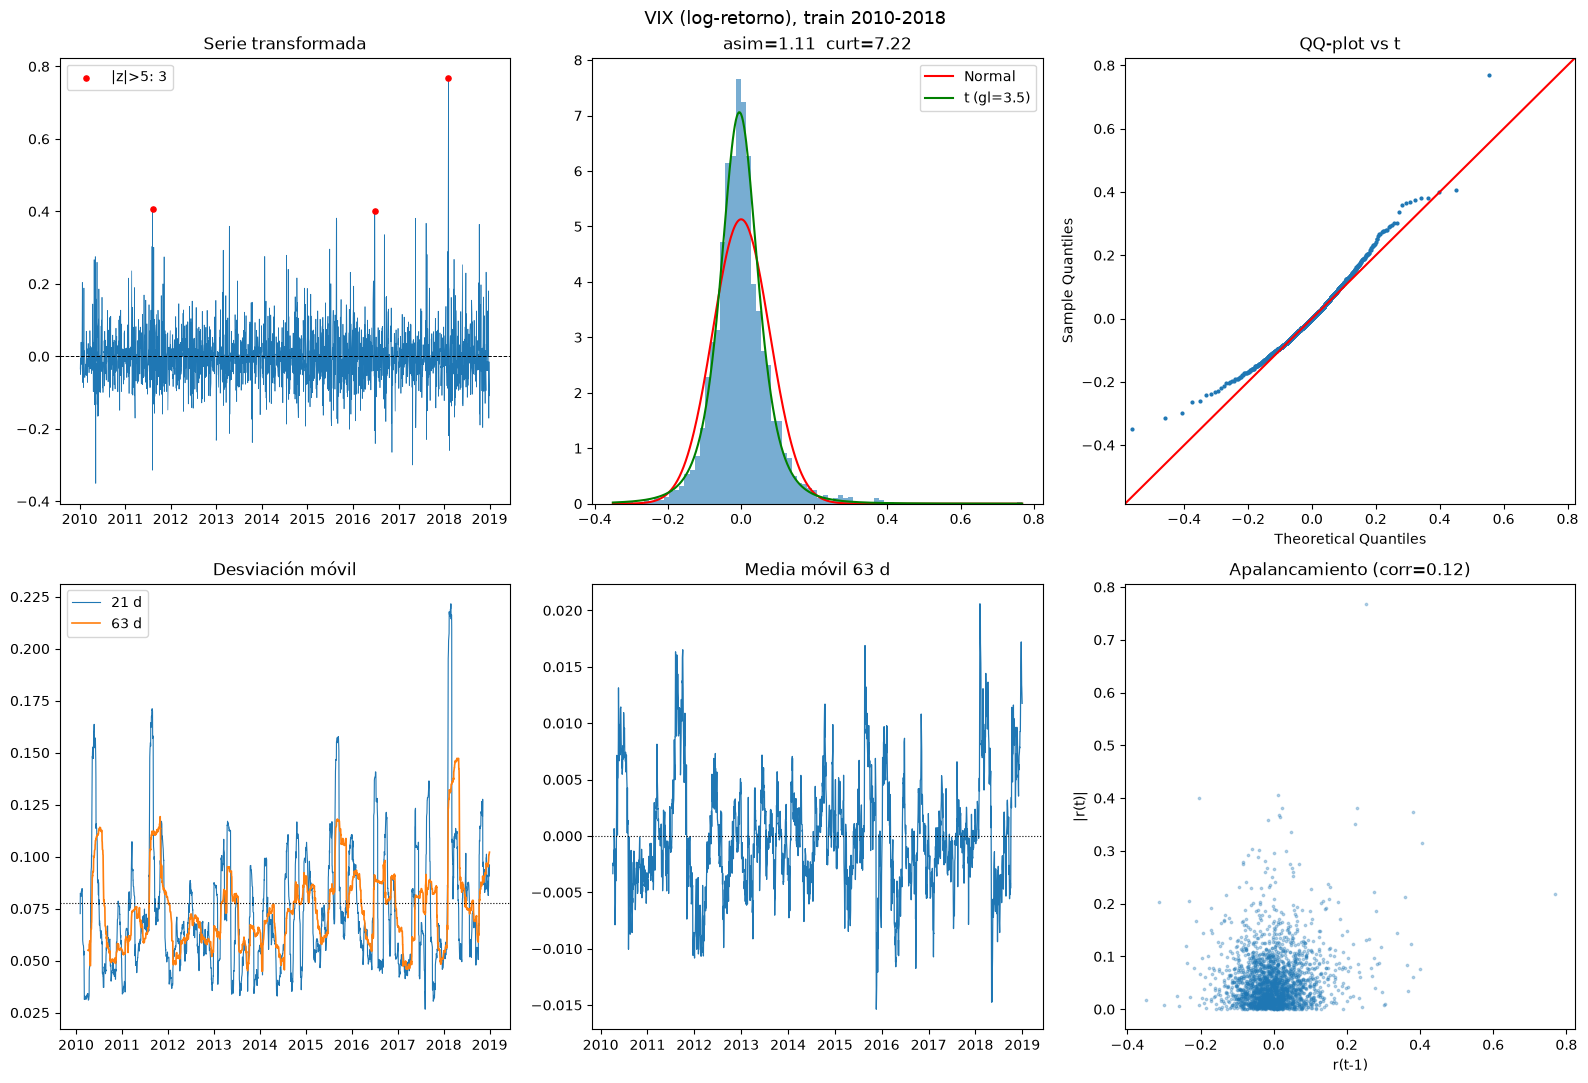

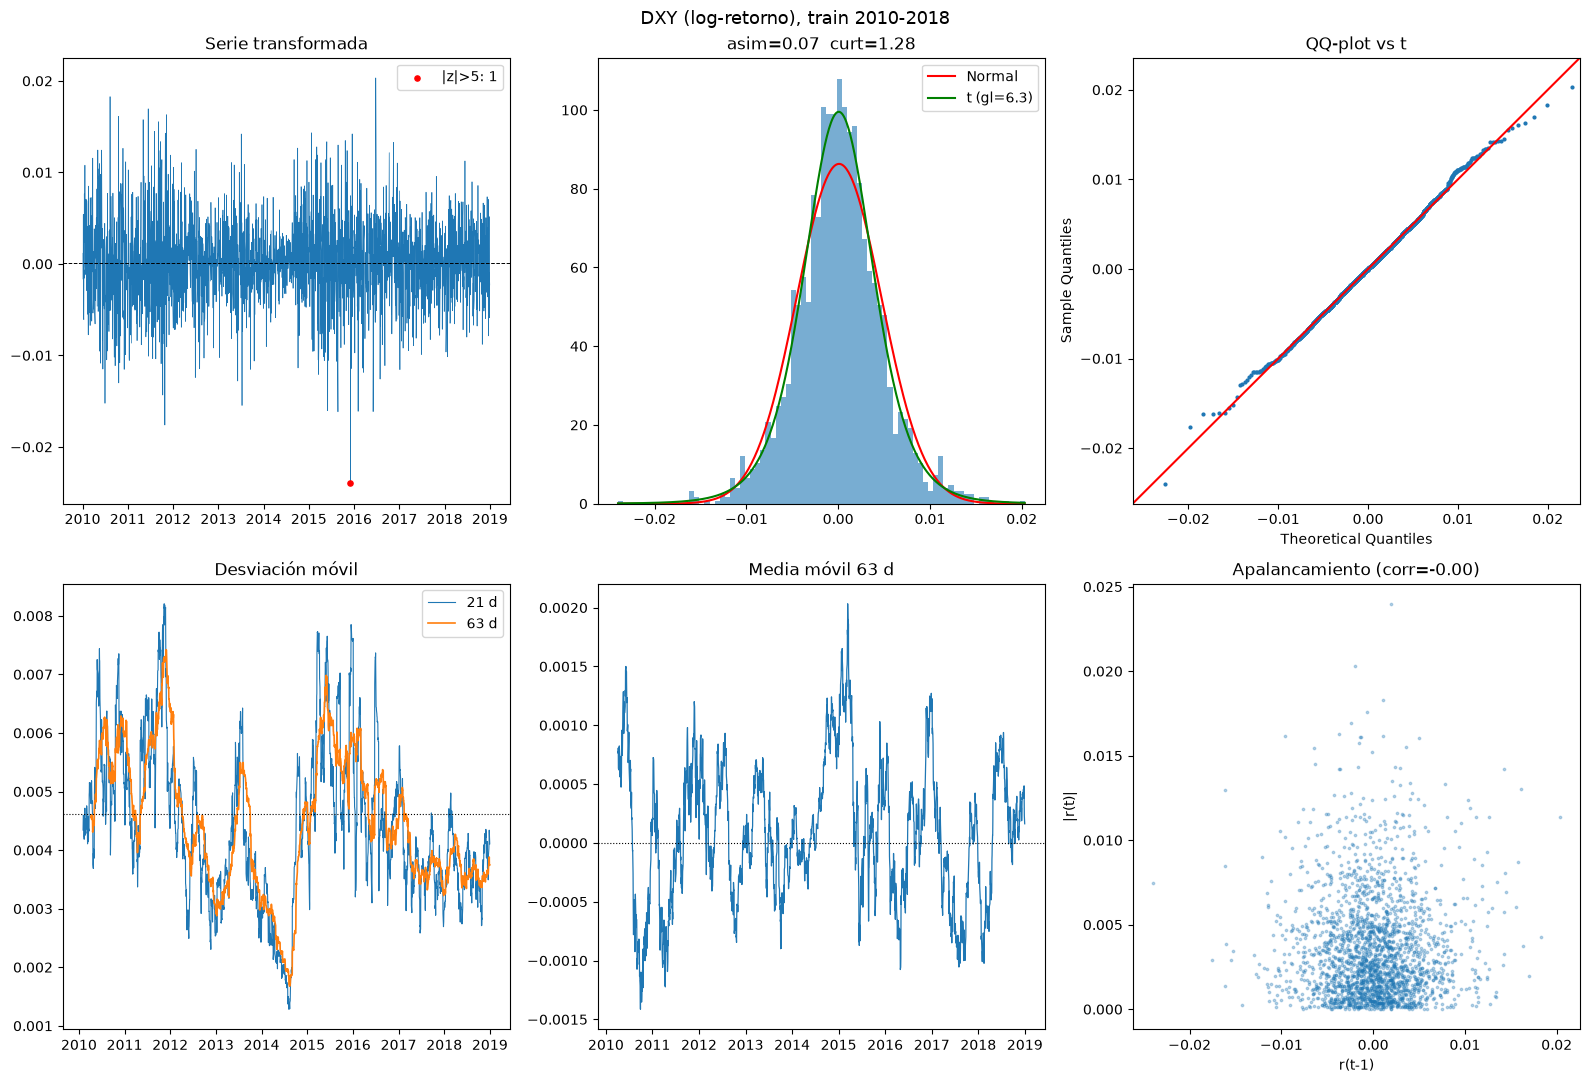

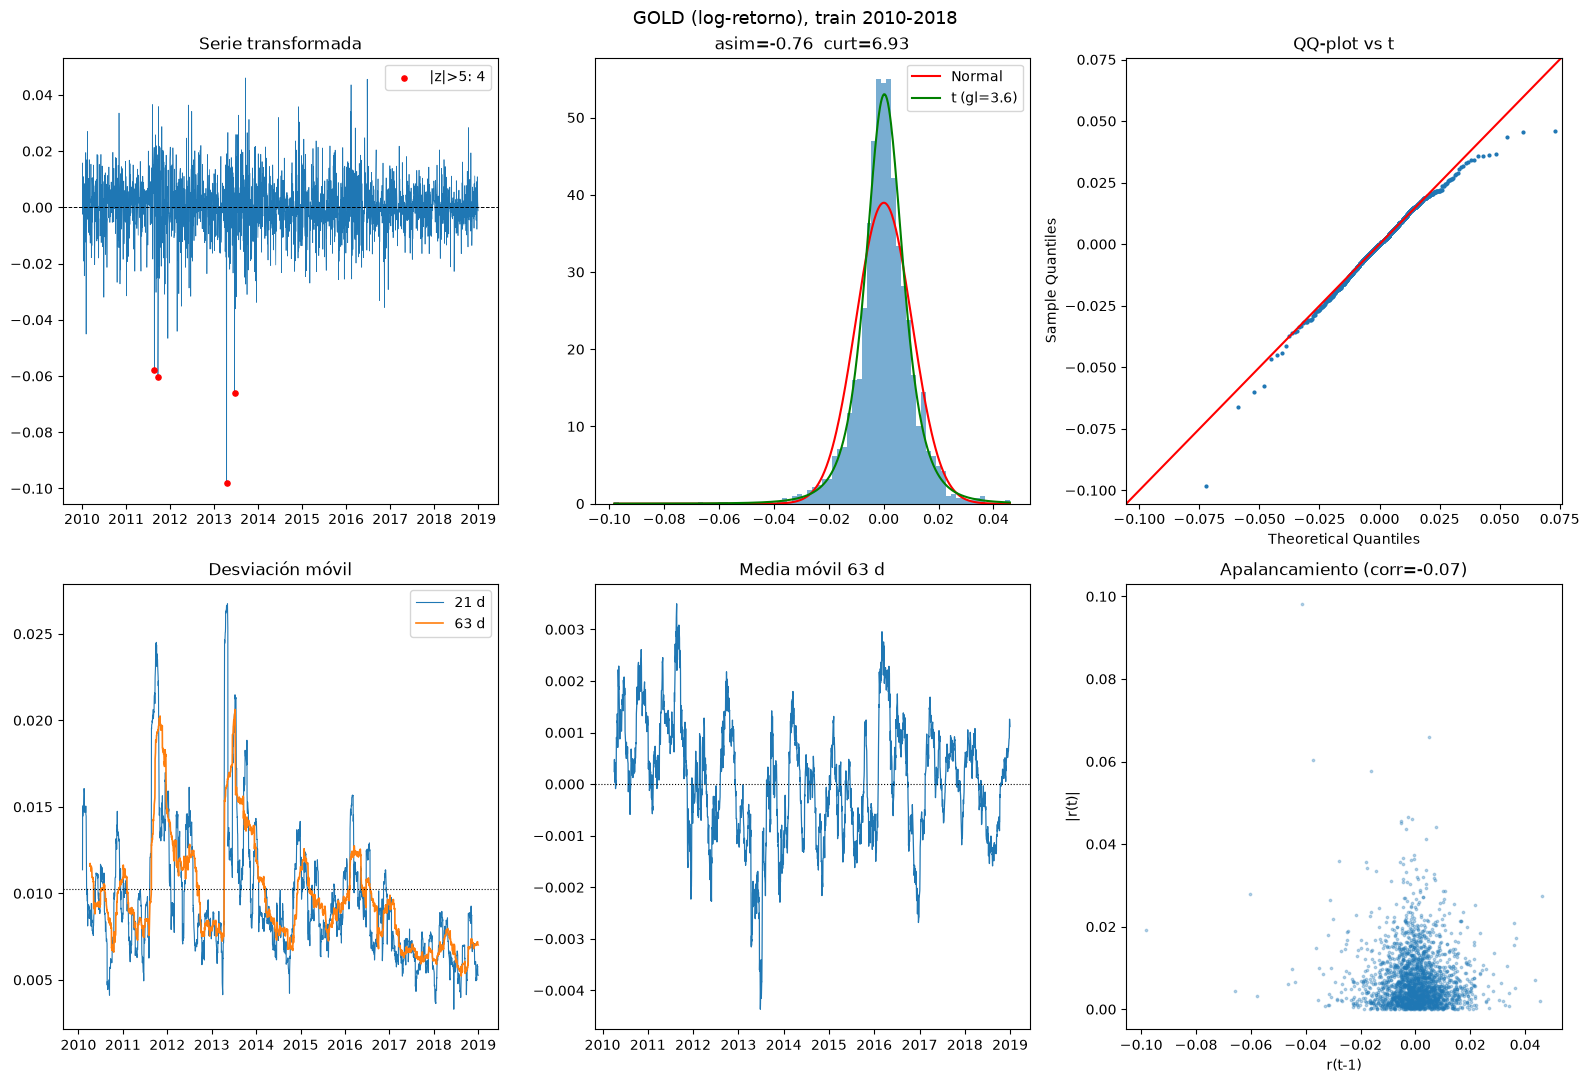

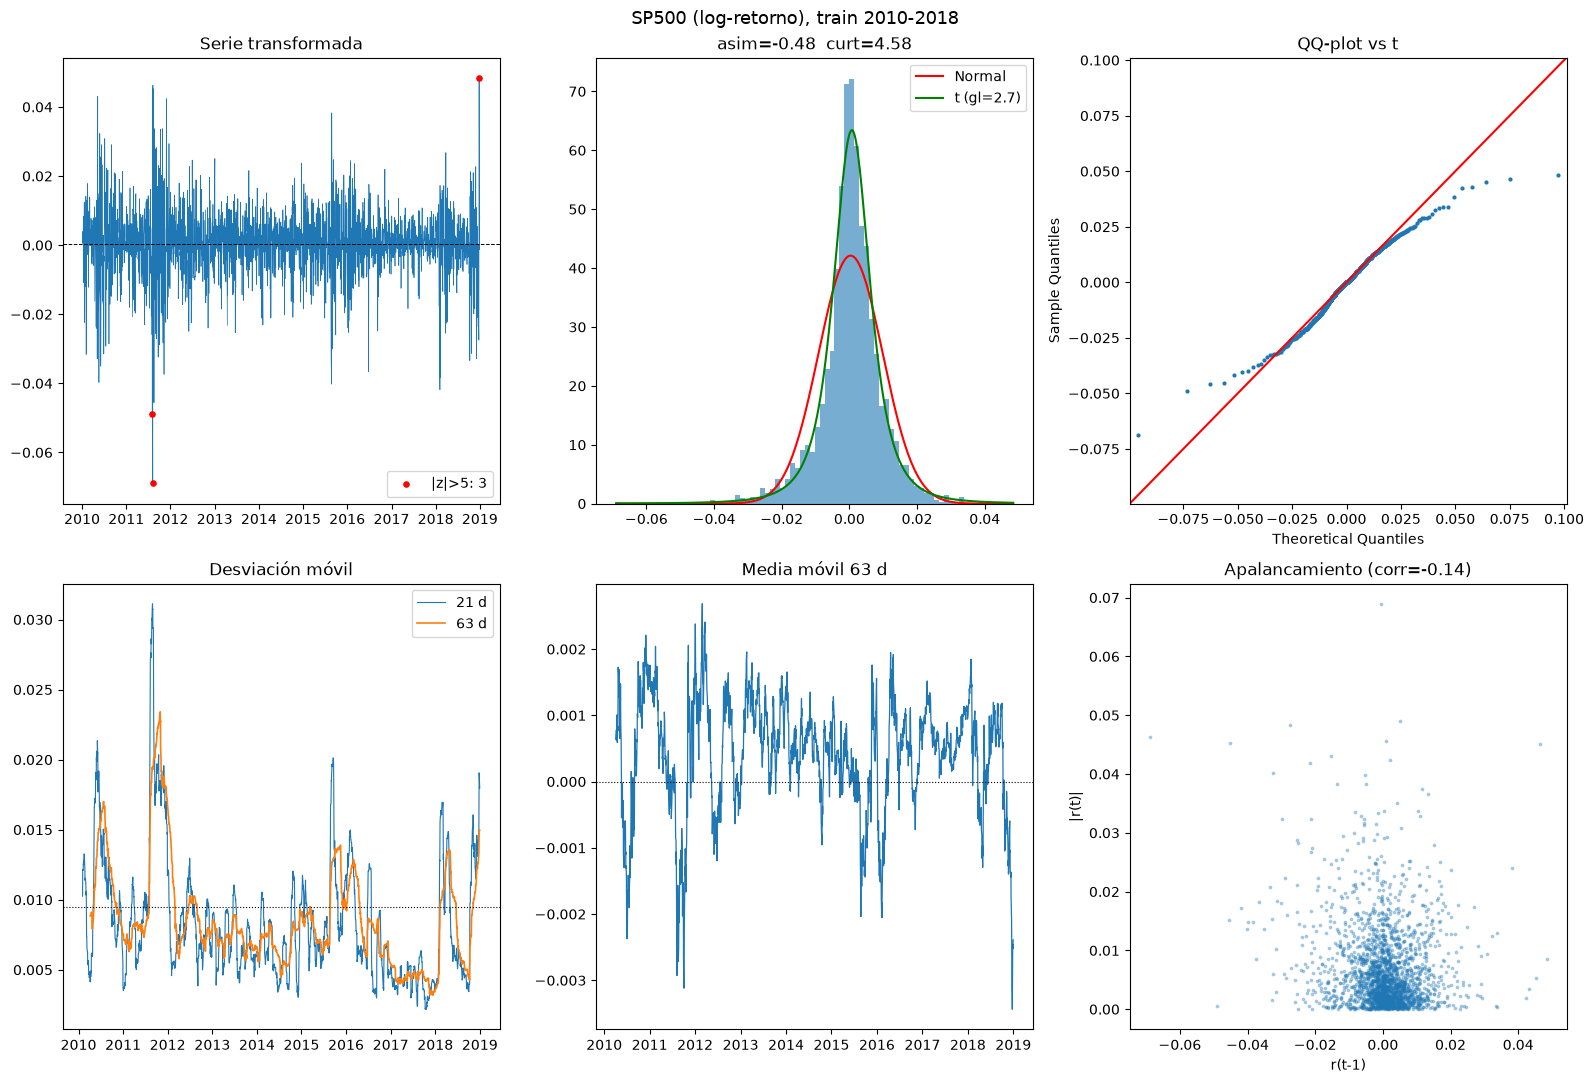

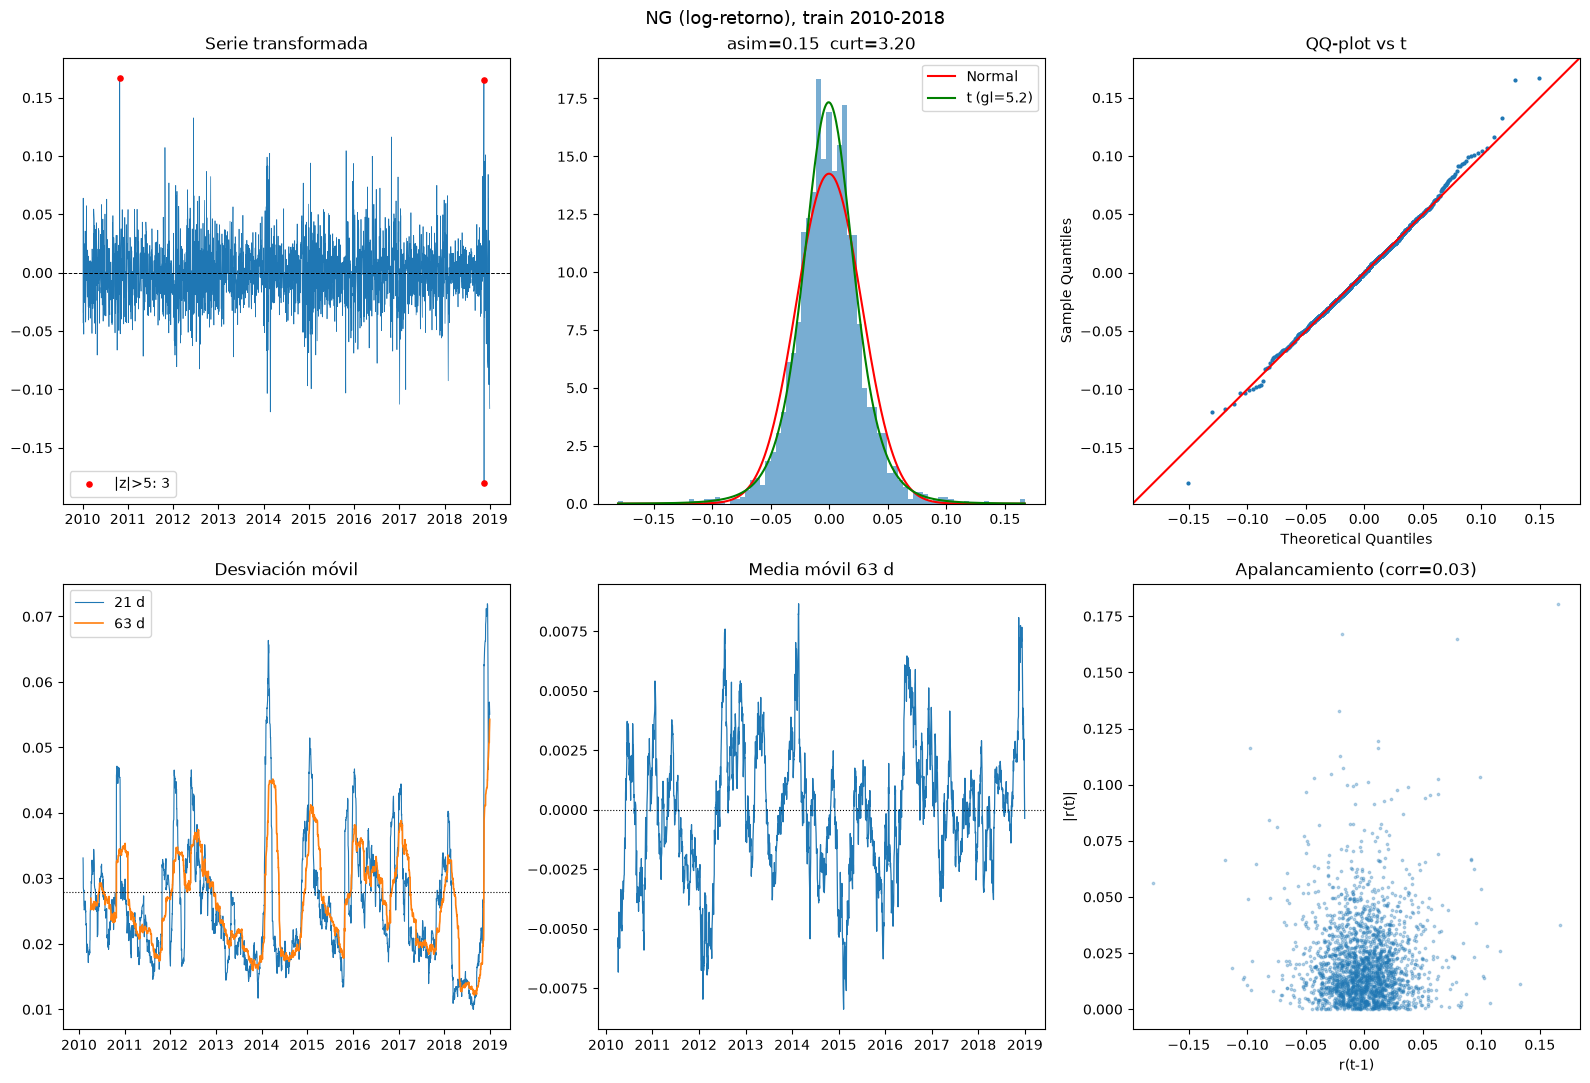

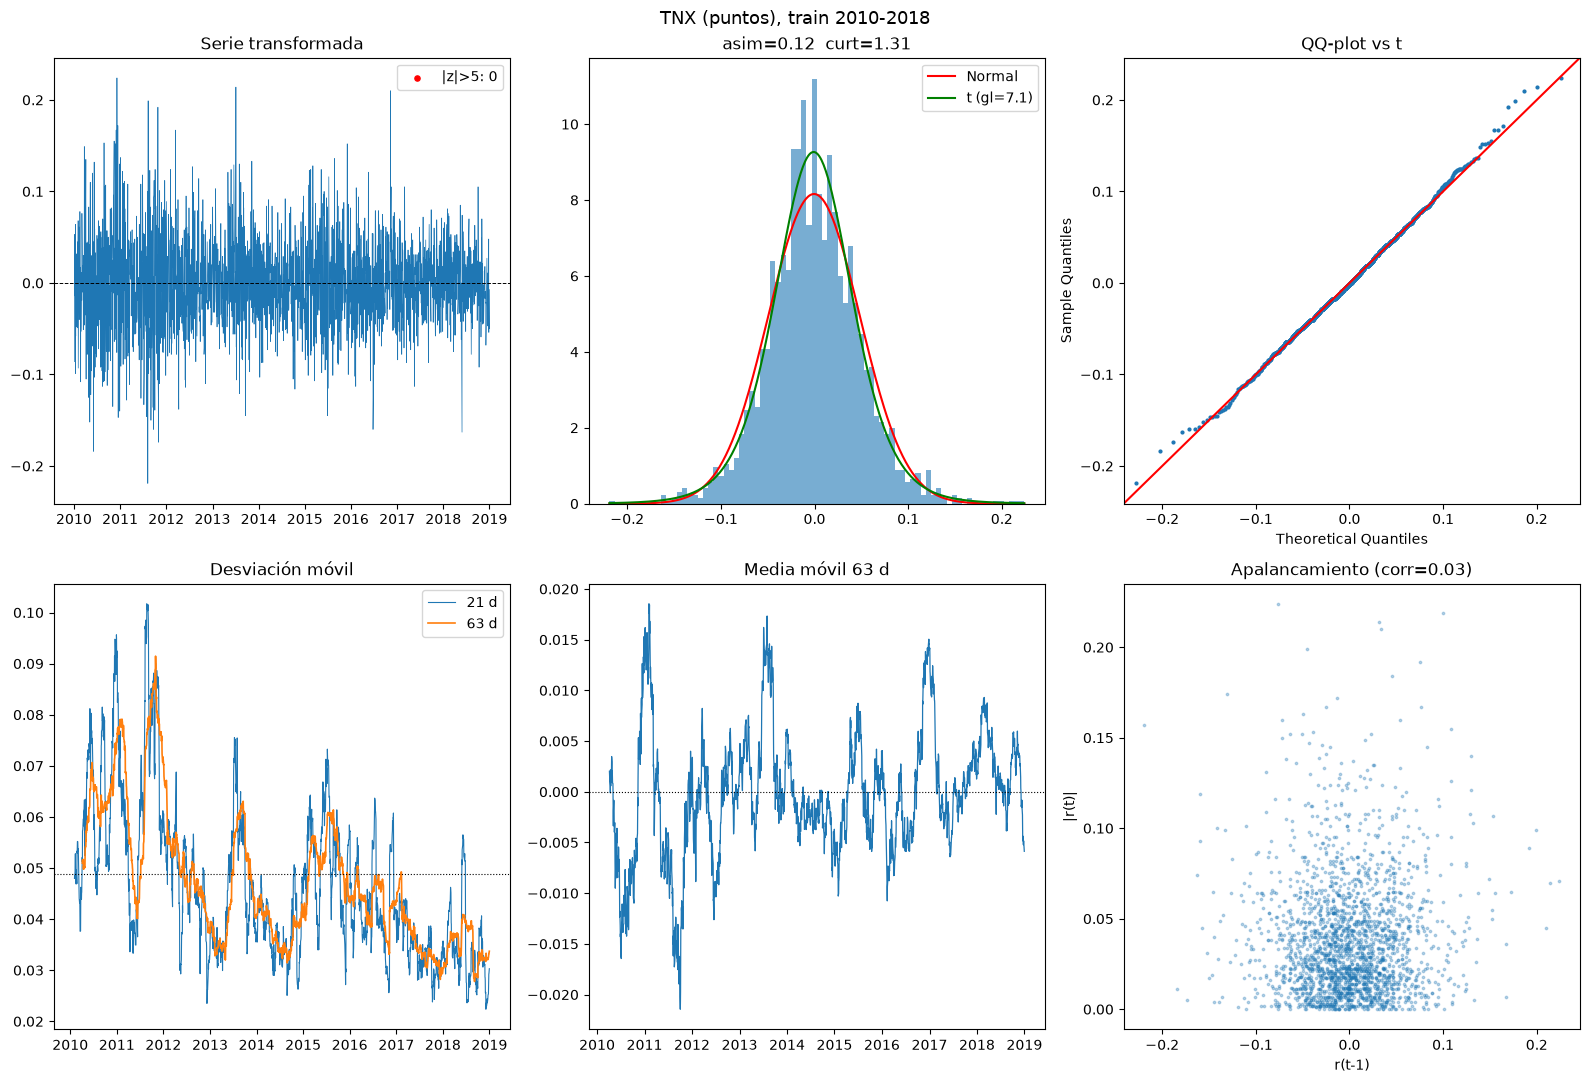

In [60]:
tr = rets_part['train']
UNID = {c: ('puntos' if TRANSF[c] == 'diff' else 'log-retorno') for c in tr.columns}

def graficar_eda(c, lags=40, w1=21, w2=63):
    r = tr[c].dropna()
    mu, sd = r.mean(), r.std()
    gl, loc_t, esc_t = stats.t.fit(r)
    out = r[(r - mu).abs() > 5 * sd]          # sigma de train

    fig, ax = plt.subplots(2, 3, figsize=(16, 11))
    fig.suptitle(f'{c} ({UNID[c]}), train 2010-2018', fontsize=13)

    # Fila 1: serie, histograma, QQ-plot
    ax[0, 0].plot(r, lw=0.5)
    ax[0, 0].scatter(out.index, out, color='red', s=14, zorder=3, label=f'|z|>5: {len(out)}')
    ax[0, 0].axhline(mu, color='k', ls='--', lw=0.7); ax[0, 0].legend()
    ax[0, 0].set_title('Serie transformada')

    ax[0, 1].hist(r, bins=80, density=True, alpha=0.6)
    xs = np.linspace(r.min(), r.max(), 400)
    ax[0, 1].plot(xs, stats.norm.pdf(xs, mu, sd), 'r', label='Normal')
    ax[0, 1].plot(xs, stats.t.pdf(xs, gl, loc_t, esc_t), 'g', label=f't (gl={gl:.1f})')
    ax[0, 1].legend(); ax[0, 1].set_title(f'asim={stats.skew(r):.2f}  curt={stats.kurtosis(r):.2f}')

    sm.qqplot(r, stats.t, distargs=(gl,), loc=loc_t, scale=esc_t, line='45', ax=ax[0, 2], markersize=2)
    ax[0, 2].set_title('QQ-plot vs t')

    # Fila 2: dependencia temporal
    #sm.graphics.tsa.plot_acf(r, lags=lags, ax=ax[1, 0], zero=False);       ax[1, 0].set_title('ACF de r')
    #sm.graphics.tsa.plot_acf(r**2, lags=lags, ax=ax[1, 1], zero=False);    ax[1, 1].set_title('ACF de r² (agrupamiento de volatilidad)')
    #sm.graphics.tsa.plot_pacf(r, lags=lags, ax=ax[1, 0], zero=False, method='ywm'); ax[1, 0].set_title('PACF de r')

    # Fila 3: regímenes y apalancamiento
    ax[1, 0].plot(r.rolling(w1).std(), lw=0.8, label=f'{w1} d')
    ax[1, 0].plot(r.rolling(w2).std(), lw=1.2, label=f'{w2} d')
    ax[1, 0].axhline(sd, color='k', ls=':', lw=0.8); ax[1, 0].legend()
    ax[1, 0].set_title('Desviación móvil')

    ax[1, 1].plot(r.rolling(w2).mean(), lw=0.9)
    ax[1, 1].axhline(0, color='k', ls=':', lw=0.8)
    ax[1, 1].set_title(f'Media móvil {w2} d')

    ax[1, 2].scatter(r.shift(1), r.abs(), s=3, alpha=0.3)
    ax[1, 2].set_xlabel('r(t-1)'); ax[1, 2].set_ylabel('|r(t)|')
    ax[1, 2].set_title(f'Apalancamiento (corr={r.shift(1).corr(r.abs()):.2f})')

    plt.tight_layout(); plt.show()

for c in tr.columns:
    graficar_eda(c)

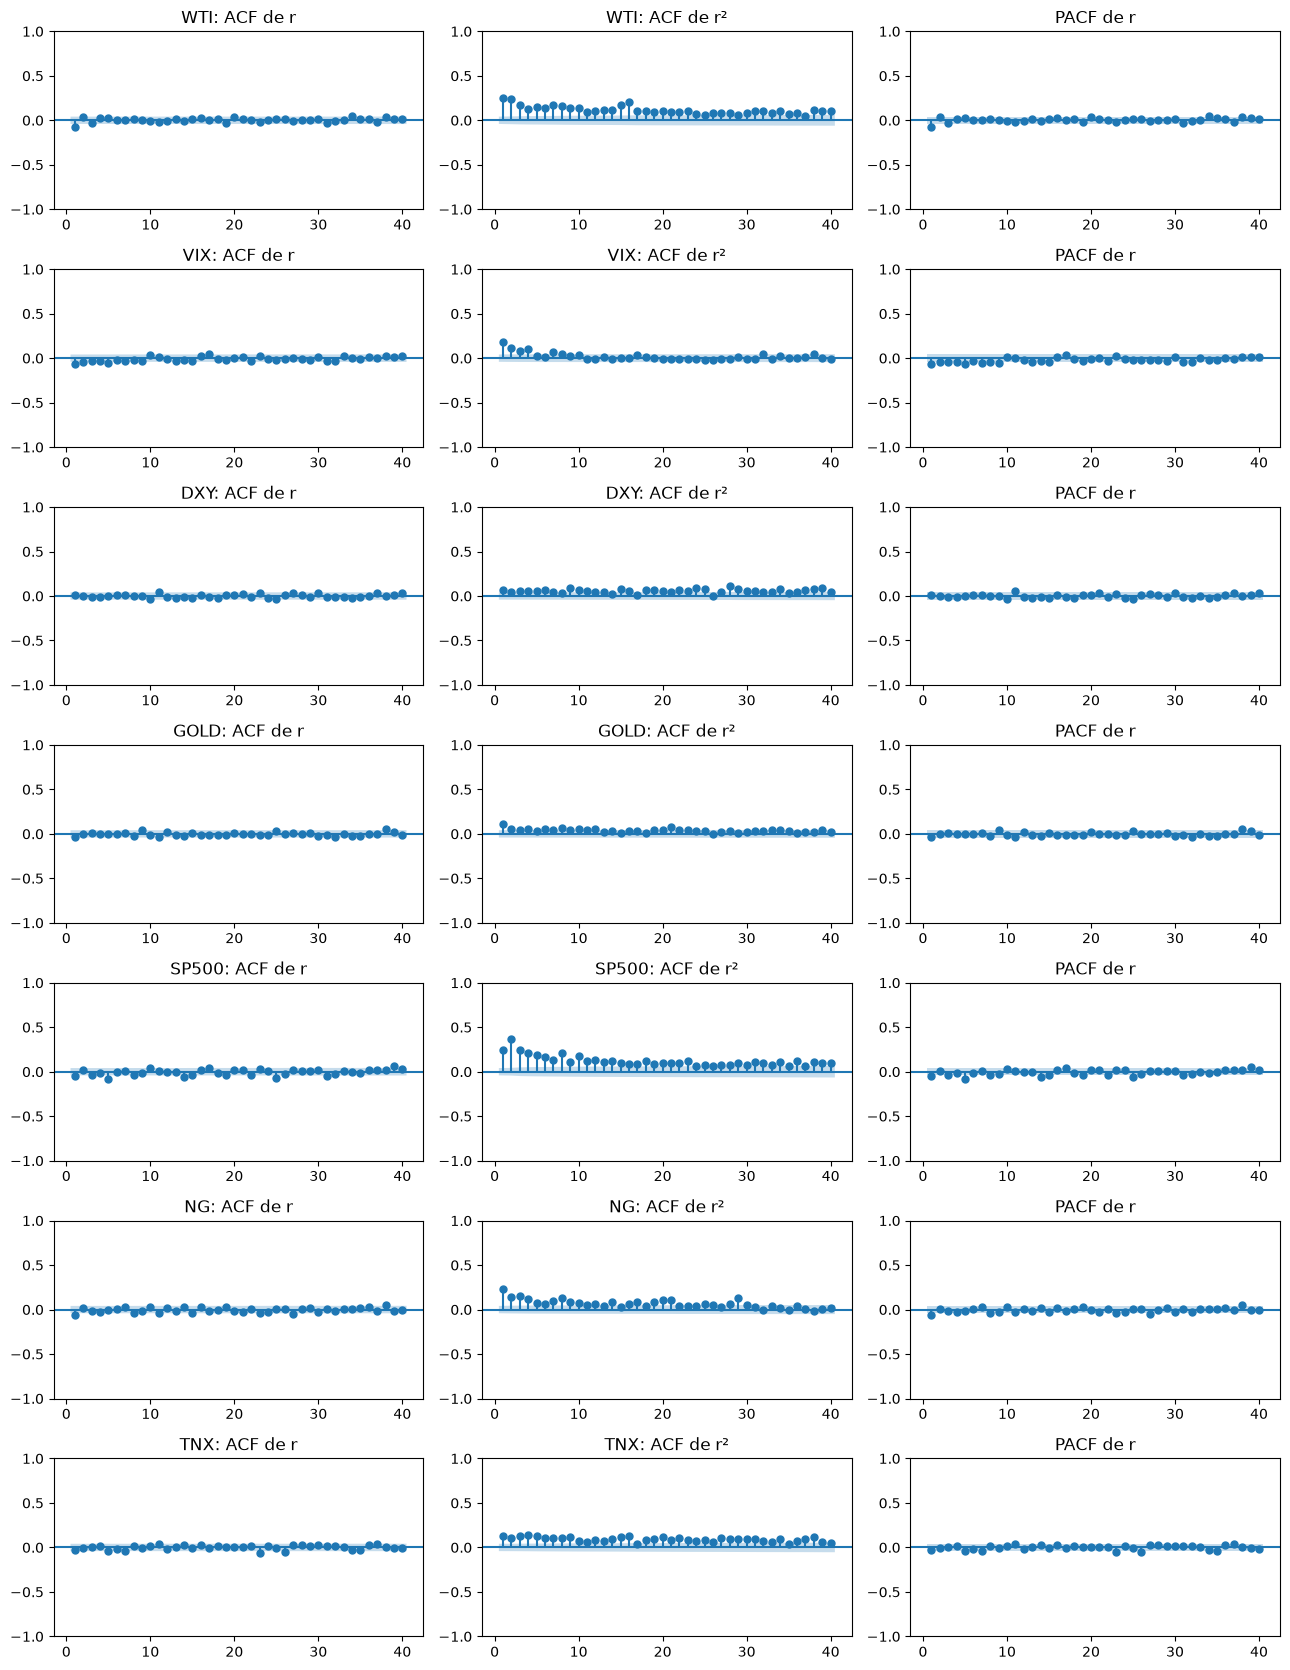

In [61]:
tr = rets_part['train']
fig, axes = plt.subplots(len(tr.columns), 3, figsize=(13, 2.4 * len(tr.columns)))
for i, c in enumerate(tr.columns):
    r = tr[c].dropna()
    sm.graphics.tsa.plot_acf(r,    lags=40, ax=axes[i, 0], zero=False, title=f'{c}: ACF de r')
    sm.graphics.tsa.plot_acf(r**2, lags=40, ax=axes[i, 1], zero=False, title=f'{c}: ACF de r²')
    sm.graphics.tsa.plot_pacf(r, lags=40, ax=axes[i, 2], zero=False, method='ywm'); axes[i, 2].set_title('PACF de r')
plt.tight_layout(); plt.show()

Estacionariedad confirmada. ADF rechaza la raíz unitaria (p ≈ 0) y KPSS no rechaza la estacionariedad en ninguna serie (estadístico entre 0,04 y 0,22, bajo el crítico del 5 %, que es 0,463). TNX es la que más se acerca (0,22). La transformación elegida funciona.
Colas pesadas en todas. Jarque-Bera rechaza la normalidad en todas (p ≈ 0). El t_gl incondicional es bajo, sobre todo en SP500 (2,66), VIX, GOLD y WTI (3,5 a 4,1). Este valor mezcla colas reales con agrupamiento de volatilidad, así que el t_gl del GARCH-t, que es condicional, saldrá más alto. Justifica el GARCH con t de Student, no la normal.
Volatilidad condicional justificada. Ljung-Box de r² y ARCH-LM rechazan en las siete (p ≤ 1e-8). Esto respalda tanto el GARCH-t como las arquitecturas con memoria (LSTM/GRU) y la salida probabilística.
Autocorrelación pequeña pero significativa en algunas. WTI (lag 1 = -0,07), VIX (-0,06, con barras negativas hasta el lag ~9) y SP500 (-0,04) rechazan Ljung-Box. Con 2.259 observaciones, el p-valor detecta efectos económicamente mínimos (≈ 0,5 % de varianza explicada). Una constante o AR(1) en el GARCH es suficiente.
Apalancamiento: corrijo lo que te dije antes. Esperaba efecto apalancamiento en WTI y SP500. Los datos lo confirman solo en el SP500 (-0,14), y en menor medida en GOLD (-0,07). En el WTI es prácticamente nulo (-0,01), así que un GARCH simétrico basta para él. Contrasta después con el parámetro γ de un GJR-GARCH. El +0,12 del VIX tiene lectura distinta: el VIX es en sí una medida de volatilidad, así que sube más después de subidas.
Riesgo extremo de referencia en train. WTI: VaR 1 % ≈ 5,7 % y ES 1 % ≈ 7,0 % diarios. Es la línea base contra la cual verás, en el Bloque 4, cuánto se queda corto un modelo entrenado en periodo normal. Solo como contexto de tu hipótesis: el log-retorno acumulado de -0,60 entre el 17 y el 21/04/2020 es muchas veces mayor que ese ES. No lo uses para decidir nada de diseño.

In [64]:
tr = rets_part['train']
exog = [c for c in tr.columns if c != 'WTI']

# 1. Granger: ¿los rezagos de la exógena ayudan a predecir el WTI? (rezagos 1 a 5)
filas = []
for c in exog:
    res = grangercausalitytests(tr[['WTI', c]].dropna(), maxlag=5)   # sin verbose
    for k in range(1, 6):
        filas.append({'exog': c, 'rezago': k, 'p': res[k][0]['ssr_ftest'][1]})
gr = pd.DataFrame(filas).pivot(index='exog', columns='rezago', values='p')
print(gr.round(4))
print("Bonferroni (30 pruebas): umbral p <", round(0.05 / 30, 4))




rezago       1       2       3       4       5
exog                                          
DXY     0.3155  0.6204  0.8231  0.9067  0.9229
GOLD    0.7282  0.1280  0.2403  0.0194  0.0073
NG      0.9524  0.9993  0.9996  0.8134  0.8101
SP500   0.0254  0.0806  0.1608  0.1989  0.0373
TNX     0.8863  0.2396  0.4273  0.5385  0.3312
VIX     0.2997  0.1789  0.2219  0.1768  0.1069
Bonferroni (30 pruebas): umbral p < 0.0017


In [66]:
filas = []
for c in exog:
    for nombre, x in {'nivel': tr[c], 'abs': tr[c].abs()}.items():
        d = pd.concat([tr['WTI'].abs().rename('y'), x.rename('x')], axis=1).dropna()
        res = grangercausalitytests(d, maxlag=5)
        for k in range(1, 6):
            filas.append({'exog': c, 'pred': nombre, 'rezago': k, 'p': res[k][0]['ssr_ftest'][1]})
gv = pd.DataFrame(filas).pivot_table(index=['exog', 'pred'], columns='rezago', values='p')
print(gv.round(4))
print("Bonferroni (60 pruebas): p <", round(0.05 / 60, 4))

rezago            1       2       3       4       5
exog  pred                                         
DXY   abs    0.0065  0.0640  0.0085  0.0228  0.0782
      nivel  0.0422  0.1368  0.2238  0.2081  0.2619
GOLD  abs    0.5959  0.8404  0.8707  0.9512  0.8859
      nivel  0.8196  0.7979  0.7525  0.8585  0.9585
NG    abs    0.1289  0.1385  0.2789  0.0070  0.0022
      nivel  0.6572  0.3250  0.3409  0.4791  0.1796
SP500 abs    0.0037  0.0092  0.0097  0.0228  0.0536
      nivel  0.1553  0.0335  0.0293  0.0083  0.0014
TNX   abs    0.9285  0.6321  0.8873  0.9468  0.7136
      nivel  0.3655  0.1677  0.0273  0.0352  0.0359
VIX   abs    0.1683  0.1155  0.1298  0.0366  0.0897
      nivel  0.6860  0.2353  0.2962  0.0638  0.0265
Bonferroni (60 pruebas): p < 0.0008


In [65]:
# 2. Colinealidad entre exógenas (VIF); > 5 preocupa, > 10 es grave
X = sm.add_constant(tr[exog])
vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])], index=exog)
print(vif.round(2))

VIX      2.89
DXY      1.21
GOLD     1.18
SP500    3.28
NG       1.01
TNX      1.29
dtype: float64


In [67]:
tr

,WTI,VIX,DXY,GOLD,SP500,NG,TNX
Date,,,,,,,
2010-01-05,0.003185,-0.035038,0.001160,0.000358,0.003111,-0.042885,-0.086
2010-01-06,0.017097,-0.009868,-0.001676,0.015795,0.000545,0.063906,0.053
2010-01-07,-0.006271,-0.005233,0.005405,-0.002468,0.003993,-0.034366,0.014
2010-01-08,0.001088,-0.050024,-0.005664,0.004491,0.002878,-0.009866,-0.014
2010-01-11,-0.002783,-0.032514,-0.006085,0.010922,0.001745,-0.052677,0.010
...,...,...,...,...,...,...,...
2018-12-24,-0.069479,0.180604,-0.004237,0.010867,-0.027487,-0.095913,-0.043
2018-12-26,0.083203,-0.170690,0.005165,0.001340,0.048403,0.021684,0.048
2018-12-27,-0.035455,-0.014908,-0.005891,0.006362,0.008526,0.027559,-0.054


In [68]:
# Variables exógenas
exog_vars = ["VIX", "DXY", "GOLD", "TNX", "SP500", "NG"]

In [71]:
target = "WTI"

In [72]:
# Verificar que los nombres existan
required = [target] + exog_vars
missing = [col for col in required if col not in train.columns]

if missing:
    raise ValueError(
        f"Revisa los nombres de estas columnas: {missing}"
    )

# Correlaciones con el retorno del WTI
pearson = train[required].corr(method="pearson")[target].drop(target)
spearman = train[required].corr(method="spearman")[target].drop(target)

corr_results = pd.DataFrame({
    "Pearson": pearson,
    "Spearman": spearman
})

display(
    corr_results.sort_values(
        "Pearson",
        key=lambda x: x.abs(),
        ascending=False
    )
)

,Pearson,Spearman
DXY,-0.897390,-0.825098
SP500,-0.595462,-0.570181
GOLD,0.576278,0.583639
NG,0.565173,0.550427
TNX,0.262157,0.267725
VIX,0.114735,0.131760


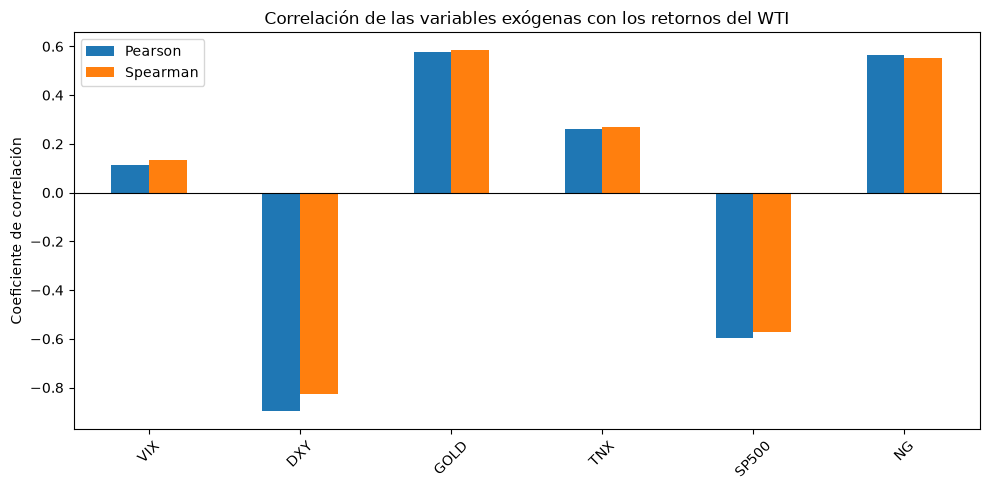

In [70]:
corr_results.plot(kind="bar", figsize=(10, 5))
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Correlación de las variables exógenas con los retornos del WTI")
plt.ylabel("Coeficiente de correlación")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [73]:
train = part["train"].copy()

In [74]:
# Retorno absoluto y retorno al cuadrado del WTI
train["WTI_abs_return"] = train[target].abs()
train["WTI_squared_return"] = train[target] ** 2

targets = [
    target,
    "WTI_abs_return",
    "WTI_squared_return"
]

vol_corr = train[exog_vars + targets].corr(
    method="spearman"
)

display(vol_corr.loc[exog_vars, targets])

,WTI,WTI_abs_return,WTI_squared_return
VIX,0.131760,0.131760,0.131760
DXY,-0.825098,-0.825098,-0.825098
GOLD,0.583639,0.583639,0.583639
TNX,0.267725,0.267725,0.267725
SP500,-0.570181,-0.570181,-0.570181
NG,0.550427,0.550427,0.550427


,VIX,DXY,GOLD,TNX,SP500,NG
0,0.114735,-0.897390,0.576278,0.262157,-0.595462,0.565173
1,0.117100,-0.897219,0.576672,0.261141,-0.596139,0.563788
2,0.120124,-0.897020,0.577201,0.260253,-0.596854,0.562602
3,0.123879,-0.896760,0.577450,0.259415,-0.597556,0.561483
4,0.127291,-0.896529,0.577797,0.258747,-0.598262,0.560383
5,0.131104,-0.896288,0.578411,0.257927,-0.599005,0.559290
6,0.133302,-0.896075,0.579052,0.257315,-0.599655,0.558385
7,0.135944,-0.895895,0.579595,0.256739,-0.600388,0.557458
8,0.138351,-0.895717,0.580049,0.256110,-0.601109,0.556572
9,0.140742,-0.895545,0.580728,0.255344,-0.601803,0.555617


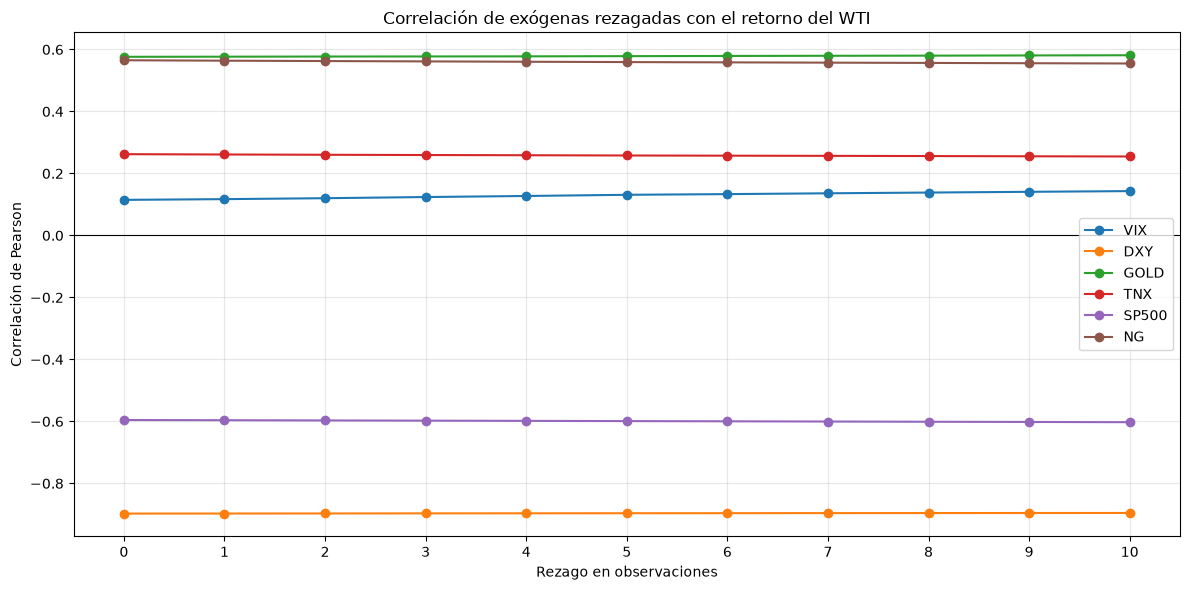

In [75]:
max_lag = 10

lag_corr = pd.DataFrame(
    index=range(max_lag + 1)
)

for var in exog_vars:
    lag_corr[var] = [
        train[var].shift(lag).corr(train[target])
        for lag in range(max_lag + 1)
    ]

display(lag_corr)

lag_corr.plot(
    figsize=(12, 6),
    marker="o"
)

plt.axhline(0, color="black", linewidth=0.8)
plt.title("Correlación de exógenas rezagadas con el retorno del WTI")
plt.xlabel("Rezago en observaciones")
plt.ylabel("Correlación de Pearson")
plt.xticks(range(max_lag + 1))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()